In [2]:
import os
import scipy.io
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import pickle
from scipy import signal
from scipy.stats import norm, t
from scipy.stats import pearsonr, kendalltau
from scipy.stats import spearmanr, kruskal, friedmanchisquare
from scipy.stats import percentileofscore
from scipy.stats import shapiro
from scipy.stats import bartlett, mannwhitneyu, wilcoxon
from scipy.io import loadmat
from sklearn.metrics import roc_curve, auc
import statsmodels.api as sm
#%pip install pingouin
import pingouin as pg
#%pip install scikit-posthocs
import scikit_posthocs as sp

In [3]:
avatars = ['Ada','Garry','Cooper','Pia']
animations = ['AU01','AU02','AU04','AU06','AU07','AU10','AU12','AU14','AU15',
    'AU17','AU23','browsAll','browsAU10','browsAU12','browsAU14','browsAU15','browsAU17','browsAU23']
AU_only_anim = animations[0:11]
print(AU_only_anim)

['AU01', 'AU02', 'AU04', 'AU06', 'AU07', 'AU10', 'AU12', 'AU14', 'AU15', 'AU17', 'AU23']


In [ ]:
main_path = "/home/hilal/MH_anim/" # repo: AU_detection_MH_project/
data_path = os.path.join(main_path, "MH_Animation_Results")  # repo: AU_detection_MH_project/data
results_path = os.path.join(main_path, "manusript_results") # repo: AU_detection_MH_project/script outputs
if not os.path.exists(results_path):
    os.makedirs(results_path)
    
os.chdir(main_path)

## Actual Values and Model Predictions

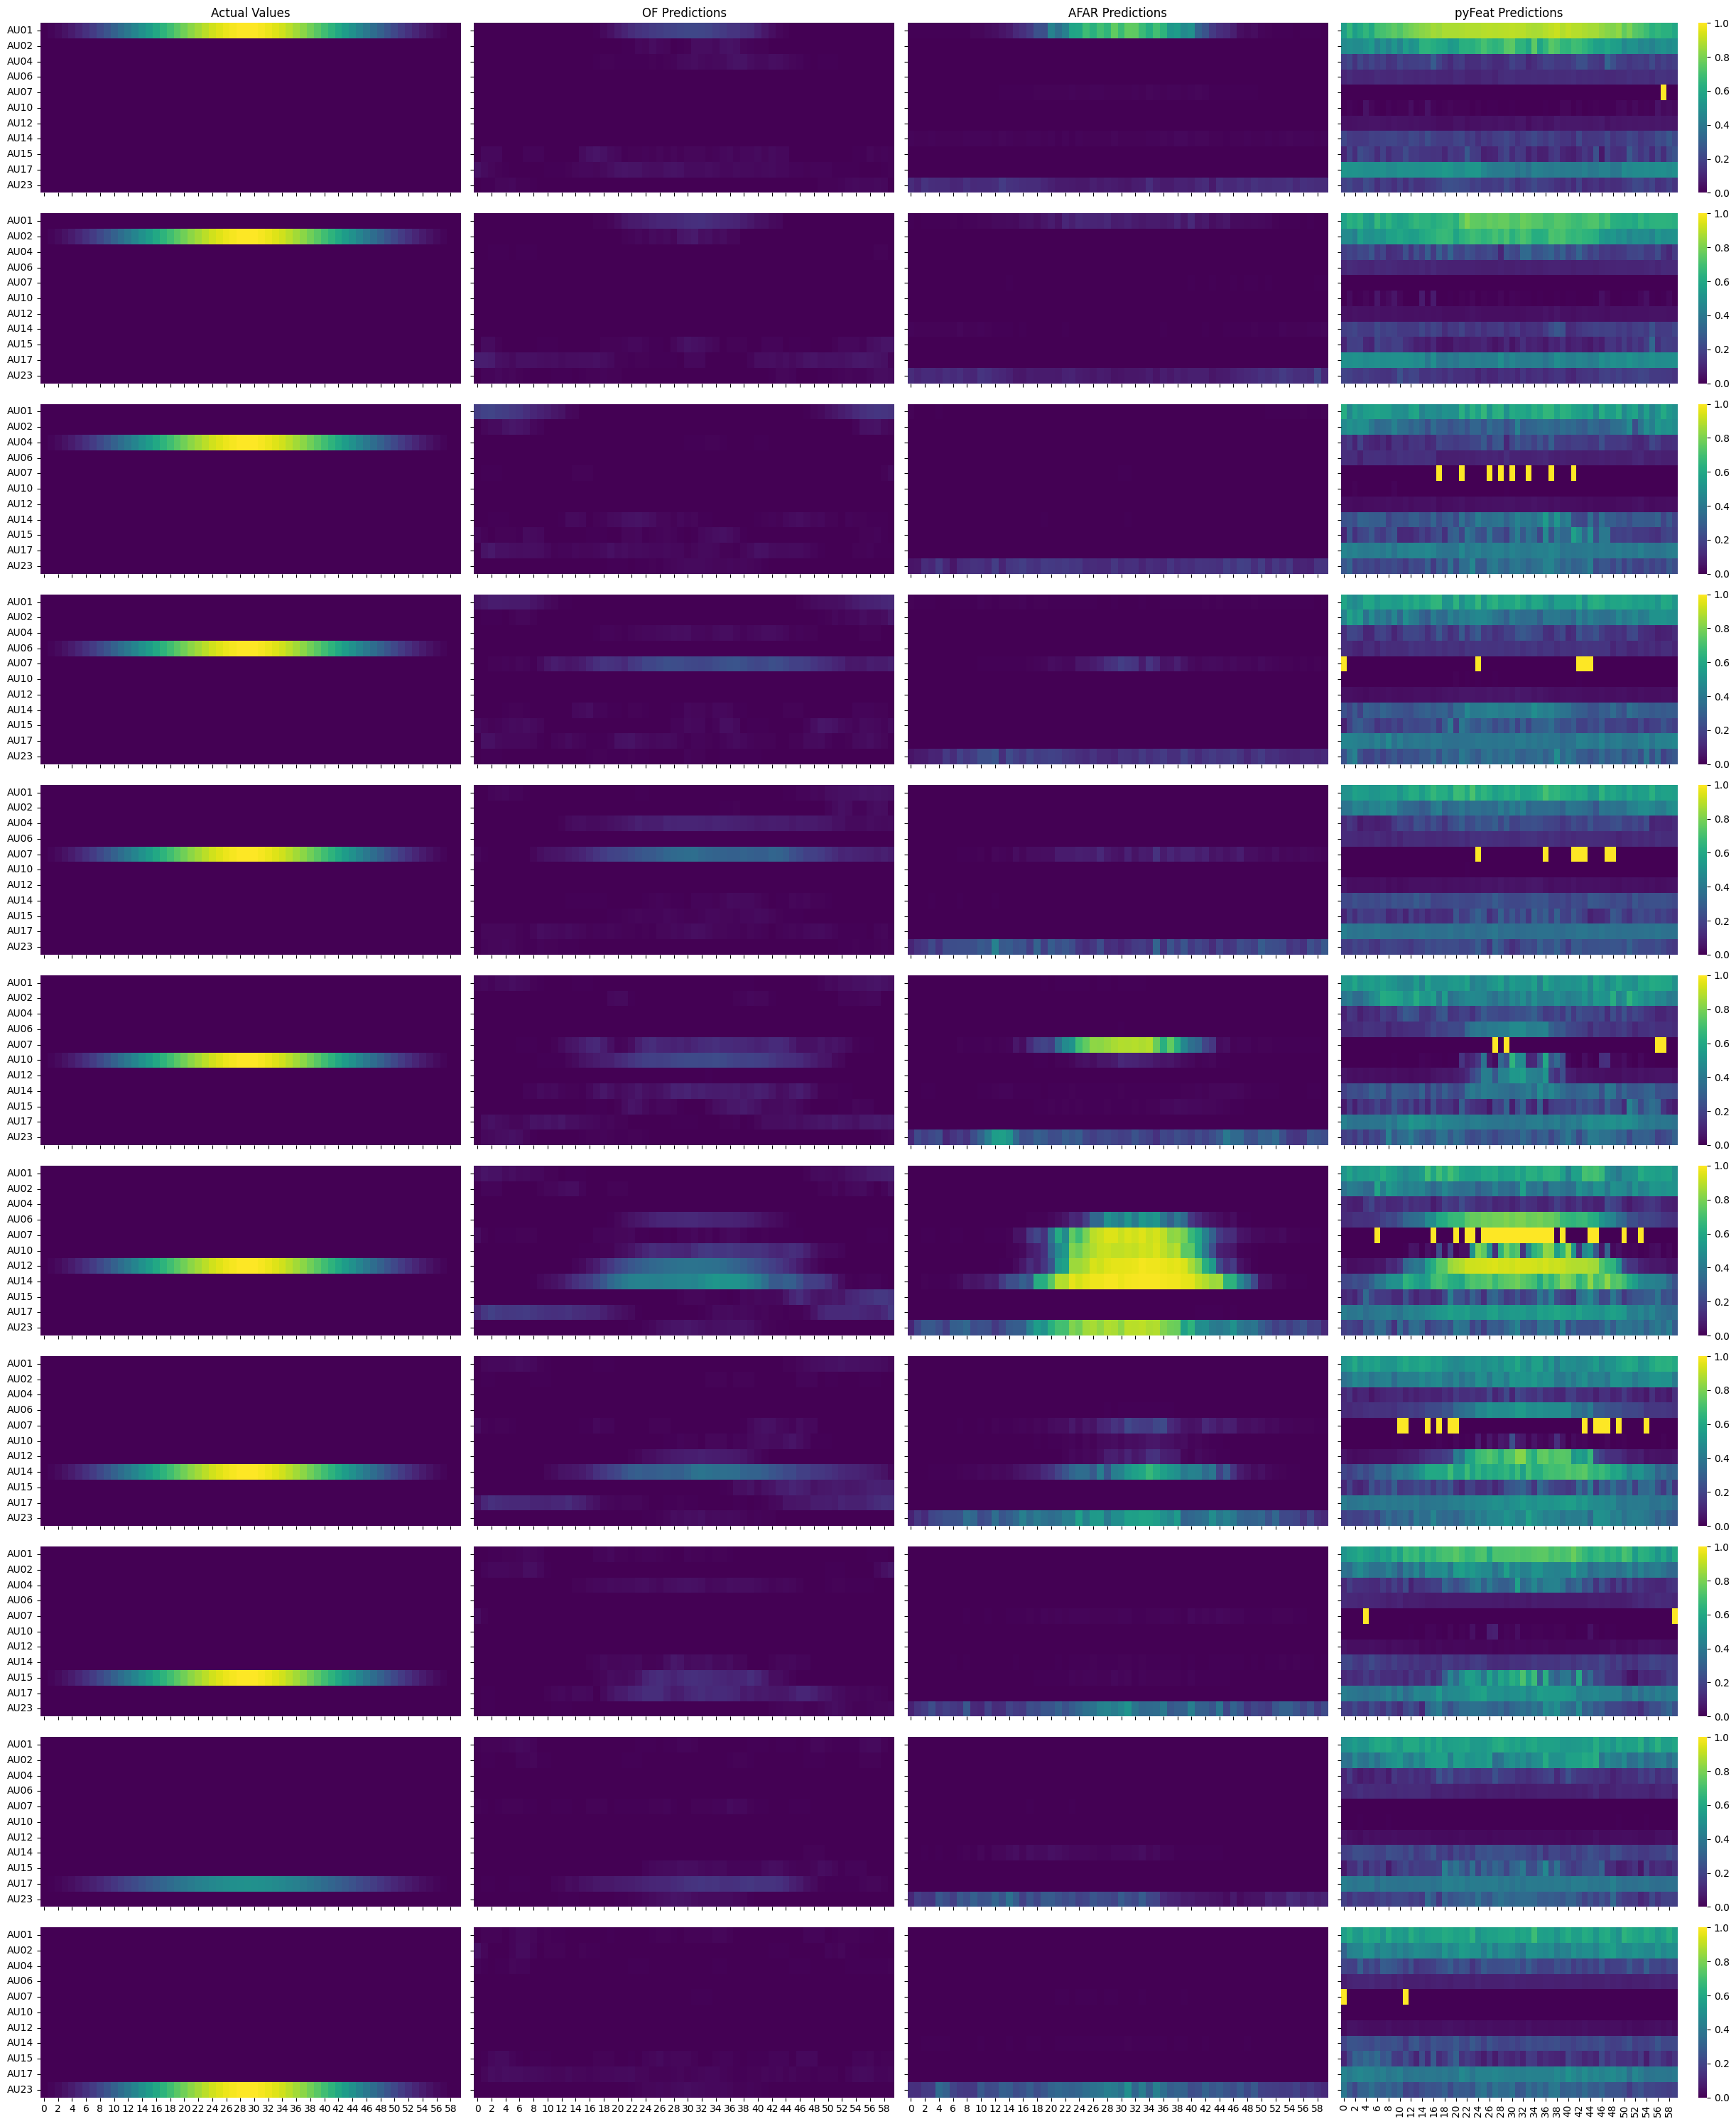

In [5]:
fig, axs = plt.subplots(len(AU_only_anim), 4, sharex=True, sharey=True, figsize=(25,30))

for anim in AU_only_anim:
  row = AU_only_anim.index(anim)
  actual_mat = loadmat(os.path.join(data_path, f"Ada_actualValues_anim_{anim}.mat"))
  actual_data = actual_mat['actual_mat']

  AFAR_pred_mat = loadmat(os.path.join(data_path, f"Ada_AFARpred_anim_{anim}.mat"))
  AFAR_pred = AFAR_pred_mat['AFAR_pred']

  OF_pred_mat = loadmat(os.path.join(data_path, f"Ada_OFpred_anim_{anim}.mat"))
  OF_pred = OF_pred_mat['normed_OF_pred']

  pyFEAT_pred_mat = loadmat(os.path.join(data_path, f"Ada_PYFEATpred_anim_{anim}.mat"))
  pyFEAT_pred = pyFEAT_pred_mat['PYFEAT_pred']

  # Plot the first heatmap using Seaborn
  sns.heatmap(actual_data.T, cmap='viridis', annot=False, cbar=False, vmin=0, vmax=1, ax=axs[row, 0])
  axs[0, 0].set_title('Actual Values')
  axs[row, 0].set_yticks(np.arange(len(AU_only_anim))+0.5, labels=AU_only_anim)
  plt.setp(axs[row, 0].get_yticklabels(), rotation=0, ha="right",
         rotation_mode="anchor")

  # Plot the second heatmap using Seaborn
  sns.heatmap(OF_pred.T, cmap='viridis', annot=False, cbar=False, vmin=0, vmax=1, ax=axs[row, 1])
  axs[0, 1].set_title('OF Predictions')
  axs[row, 1].set_yticks(np.arange(len(AU_only_anim))+0.5, labels=AU_only_anim)
  plt.setp(axs[row, 1].get_yticklabels(), rotation=0, ha="right",
         rotation_mode="anchor")

  # Plot the third heatmap using Seaborn
  sns.heatmap(AFAR_pred.T, cmap='viridis', annot=False, cbar=False, vmin=0, vmax=1, ax=axs[row, 2])
  axs[0, 2].set_title('AFAR Predictions')
  axs[row, 2].set_yticks(np.arange(len(AU_only_anim))+0.5, labels=AU_only_anim)
  plt.setp(axs[row, 2].get_yticklabels(), rotation=0, ha="right",
         rotation_mode="anchor")

  # Plot the fourth heatmap using Seaborn
  sns.heatmap(pyFEAT_pred.T, cmap='viridis', annot=False, cbar=True, vmin=0, vmax=1, ax=axs[row, 3])
  axs[0, 3].set_title('pyFeat Predictions')
  axs[row, 3].set_yticks(np.arange(len(AU_only_anim))+0.5, labels=AU_only_anim)
  plt.setp(axs[row, 3].get_yticklabels(), rotation=0, ha="right",
         rotation_mode="anchor")

  # Adjust layout for better spacing
  plt.tight_layout()

  # Show the plot
plt.show()

## Calculate Classification Metrics and Create a DataFrame

['Ada_AU01']
PREC: Cannot be divided by zero
F1: SEN or PREC is None
['Ada_AU02']
PREC: Cannot be divided by zero
F1: SEN or PREC is None
PREC: Cannot be divided by zero
F1: SEN or PREC is None
['Ada_AU04']
PREC: Cannot be divided by zero
F1: SEN or PREC is None
PREC: Cannot be divided by zero
F1: SEN or PREC is None
['Ada_AU06']
PREC: Cannot be divided by zero
F1: SEN or PREC is None
PREC: Cannot be divided by zero
F1: SEN or PREC is None
['Ada_AU07']
PREC: Cannot be divided by zero
F1: SEN or PREC is None
F1: Cannot be divided by zero
['Ada_AU10']
PREC: Cannot be divided by zero
F1: SEN or PREC is None
F1: Cannot be divided by zero
['Ada_AU12']
F1: Cannot be divided by zero
['Ada_AU14']
PREC: Cannot be divided by zero
F1: SEN or PREC is None
['Ada_AU15']
PREC: Cannot be divided by zero
F1: SEN or PREC is None
F1: Cannot be divided by zero
['Ada_AU17']
PREC: Cannot be divided by zero
F1: SEN or PREC is None
PREC: Cannot be divided by zero
F1: SEN or PREC is None
['Ada_AU23']
PREC: Can

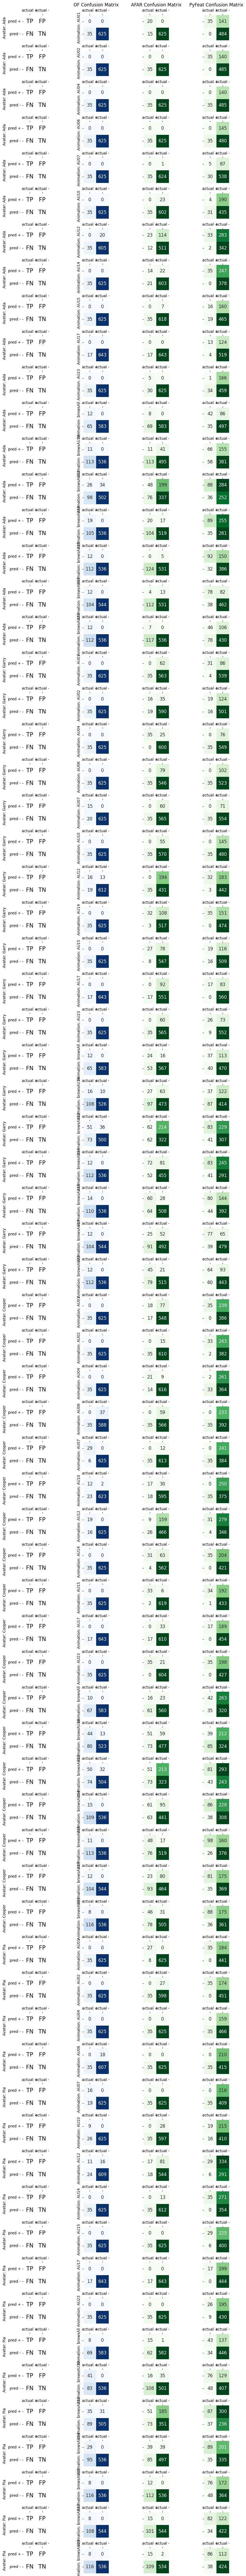

In [ ]:
def sensitivity(TP,FN):  # True Positive Rate
  if (len(TP)+len(FN)) == 0:
    print("SEN: Cannot be divided by zero")
    SEN = None
  else:
    SEN = len(TP) / (len(TP)+len(FN))
  return SEN

def FPR(FP,TN):
  if (len(FP)+len(TN)) == 0:
    print("FPR: Cannot be divided by zero")
    FPR = None
  else:
    FPR = len(FP) / (len(FP)+len(TN))
  return FPR

def specificity(TN,FP):
  if (len(TN)+len(FP)) == 0:
    print("SPEC: Cannot be divided by zero")
    SPEC = None
  else:
    SPEC = len(TN) / (len(TN)+len(FP))
  return SPEC

def prec(TP,FP):
  if (len(TP)+len(FP)) == 0:
    print("PREC: Cannot be divided by zero")
    PREC = None
  else:
    PREC = len(TP) / (len(TP)+len(FP))
  return PREC

def F1_score(SEN,PREC):
  if not isinstance(PREC, (int,float)) and isinstance(SEN, (int,float)):
    print("F1: SEN or PREC is None")
    F1 = 0
  else:
    if (SEN+PREC) == 0:
      print("F1: Cannot be divided by zero")
      F1 = 0
    else:
      F1 = 2*((SEN*PREC)/(SEN+PREC))
  return F1


list_keys_2D = [['TP', 'FP'],['FN', 'TN']]
threshold= 0.2
plot_row=-1
classification_metrics_all_OF = {}
classification_metrics_all_AFAR = {}
classification_metrics_all_pyFEAT = {}

#for threshold in thresholds[1]:
fig, axs = plt.subplots(len(animations)*len(avatars), 4, sharex=True, sharey=True, figsize=(10,96))

for avatar in avatars:
  for anim in animations:
    all_var_dict = {
        'avatar': avatar,
        'animation': anim
        }

    classification_metrics_all_OF.update(all_var_dict)
    classification_metrics_all_AFAR.update(all_var_dict)
    classification_metrics_all_pyFEAT.update(all_var_dict)

    print([avatar + '_' + anim])
    plot_row = plot_row+1

    anim_ind = animations.index(anim)

    actual_mat = loadmat(os.path.join(data_path, f"{avatar}_actualValues_anim_{anim}.mat"))
    actual_data = actual_mat['actual_mat']

    AFAR_pred_mat = loadmat(os.path.join(data_path, f"{avatar}_AFARpred_anim_{anim}.mat"))
    AFAR_pred = AFAR_pred_mat['AFAR_pred']

    OF_pred_mat = loadmat(os.path.join(data_path, f"{avatar}_OFpred_anim_{anim}.mat"))
    OF_pred = OF_pred_mat['normed_OF_pred']

    pyFEAT_pred_mat = loadmat(os.path.join(data_path, f"{avatar}_PYFEATpred_anim_{anim}.mat"))
    pyFEAT_pred = pyFEAT_pred_mat['PYFEAT_pred']

    #calculate pred labels
    y_true = np.where(actual_data > threshold, 1, 0)
    y_class_AFAR = np.where(AFAR_pred > threshold, 1, 0)
    y_class_OF = np.where(OF_pred > threshold, 1, 0)
    y_class_pyFEAT = np.where(pyFEAT_pred > threshold, 1, 0)

    '''first figure'''
    df = pd.DataFrame([[0,0], [0,0]],
                    columns=['actual +', 'actual -'], index=['pred +', 'pred -'])
    sns.heatmap(df, annot=False, cmap='Greys', fmt='d', cbar=False, square=True, ax=axs[plot_row, 0])

    for i in range(len(df.index)):
      for j in range(len(df.columns)):
          value = list_keys_2D[i][j]
          axs[plot_row, 0].text(j+0.5, i+0.5, value, ha='center', va='center', fontsize=15)
    axs[plot_row, 0].tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
    axs[plot_row,0].set_ylabel(f'Avatar: {avatar}')
    ''''''''''''''''''''''''''''''''''''''''''''''''''''''''''''''''''
    OF_TP = []; AFAR_TP = []; pyFEAT_TP = []; false_detections_OF = [];
    OF_TN = []; AFAR_TN = []; pyFEAT_TN = []; false_detections_AFAR = [];
    OF_FP = []; AFAR_FP = []; pyFEAT_FP = []; false_detections_pyFEAT = [];
    OF_FN = []; AFAR_FN = []; pyFEAT_FN = [];

    ''' OF '''

    for fr in range(actual_data.shape[0]):
      for col in range(actual_data.shape[1]):
        prediction = OF_pred[fr,col]
        actual = actual_data[fr,col]
        if actual > threshold and  prediction > threshold:
            OF_TP.append(prediction)
        elif actual > threshold and prediction <= threshold:
            OF_FN.append(1)
        elif actual <= threshold and prediction > threshold:
            OF_FP.append(prediction)
            false_AU = animations[col]
            false_detections_OF.append(false_AU)
        elif actual <= threshold and prediction <= threshold:
            OF_TN.append(1)

    confusion_metrics_percentages_OF ={
          "TP_perc": round(len(OF_TP)/len(actual_data.flatten())*100),
          "FP_perc": round(len(OF_FP)/len(actual_data.flatten())*100),
          "TN_perc": round(len(OF_TN)/len(actual_data.flatten())*100),
          "FN_perc": round(len(OF_FN)/len(actual_data.flatten())*100)
      }

    confusion_metrics_OF ={
          "TP": len(OF_TP),
          "FP": len(OF_FP),
          "TN": len(OF_TN),
          "FN": len(OF_FN),
          "false_detections": false_detections_OF
      }

    classification_metrics_all_OF.update(confusion_metrics_OF)
    classification_metrics_all_OF.update(confusion_metrics_percentages_OF)

    df = pd.DataFrame([[confusion_metrics_OF['TP'], confusion_metrics_OF['FP']], [confusion_metrics_OF['FN'], confusion_metrics_OF['TN']]],
                    columns=['actual +', 'actual -'], index=['pred +', 'pred -'])

    sns.heatmap(df, annot=True, annot_kws={'size': 12}, cmap='Blues', fmt='d', cbar=False, square=True, ax=axs[plot_row, 1])
    axs[plot_row, 1].tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
    axs[0, 1].set_title('OF Confusion Matrix')
    axs[plot_row,1].set_ylabel(f'Animation: {anim}')

    confusion_values_OF ={
          "TP": OF_TP,
          "FP": OF_FP,
          "TN": OF_TN,
          "FN": OF_FN
      }

    df = pd.DataFrame.from_dict(confusion_values_OF, orient='index')
    df = df.T
    #df.to_csv(f'{avatar}_{anim}_OF_confusion_values_threshold_{threshold}.csv')

    SEN_OF = sensitivity(OF_TP, OF_FN)
    FPR_OF = FPR(OF_FP, OF_TN)
    SPEC_OF = specificity(OF_TN, OF_FP)
    PREC_OF = prec(OF_TP, OF_FP)
    F1_OF = F1_score(SEN_OF, PREC_OF)

    confusion_scores_OF={
        "TPR": SEN_OF,
        "FPR": FPR_OF,
        "F1_score": F1_OF
    }

    classification_metrics_all_OF.update(confusion_scores_OF)

    df = pd.DataFrame.from_dict(confusion_scores_OF, orient='index')
    df = df.T
    # Save DataFrame to CSV file
    #df.to_csv(f'{avatar}_{anim}_OF_confusion_scores_threshold_{threshold}.csv')

    #calculate AUC and plot ROC
    fpr, tpr, _ = roc_curve(y_true.flatten(), OF_pred.flatten())
    roc_auc = auc(fpr, tpr)
    AUC_dict={
        'AUC': roc_auc
    }
    classification_metrics_all_OF.update(AUC_dict)
    df_OF = pd.DataFrame.from_dict(classification_metrics_all_OF, orient='index')
    df_OF = df_OF.T
    #print(df_OF)
    df_OF.to_csv(os.path.join(results_path, f'{avatar}_{anim}_OF_classification_metrics_all_threshold_{threshold}.csv'))

    ''' AFAR '''
    for fr in range(actual_data.shape[0]):
      for col in range(actual_data.shape[1]):
        prediction = AFAR_pred[fr,col]
        actual = actual_data[fr,col]
        if actual > threshold and  prediction > threshold:
            AFAR_TP.append(prediction)
        elif actual > threshold and prediction <= threshold:
            AFAR_FN.append(1)
        elif actual <= threshold and prediction > threshold:
            AFAR_FP.append(prediction)
            false_AU = animations[col]
            false_detections_AFAR.append(false_AU)
        elif actual <= threshold and prediction <= threshold:
            AFAR_TN.append(1)

    confusion_metrics_percentages_AFAR ={
          "TP_perc": round(len(AFAR_TP)/len(actual_data.flatten())*100),
          "FP_perc": round(len(AFAR_FP)/len(actual_data.flatten())*100),
          "TN_perc": round(len(AFAR_TN)/len(actual_data.flatten())*100),
          "FN_perc": round(len(AFAR_FN)/len(actual_data.flatten())*100)
      }

    confusion_metrics_AFAR = {
          "TP": len(AFAR_TP),
          "FP": len(AFAR_FP),
          "TN": len(AFAR_TN),
          "FN": len(AFAR_FN),
          "false_detections": false_detections_AFAR
    }

    classification_metrics_all_AFAR.update(confusion_metrics_AFAR)
    classification_metrics_all_AFAR.update(confusion_metrics_percentages_AFAR)

    df = pd.DataFrame([[confusion_metrics_AFAR['TP'],
                        confusion_metrics_AFAR['FP']],
                        [confusion_metrics_AFAR['FN'],
                          confusion_metrics_AFAR['TN']]],
                    columns=['actual +', 'actual -'], index=['pred +', 'pred -'])

    sns.heatmap(df, annot=True, annot_kws={'size': 12}, cmap='Greens', fmt='d', cbar=False, square=True, ax=axs[plot_row, 2])
    axs[plot_row, 2].tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
    axs[0, 2].set_title('AFAR Confusion Matrix')

    confusion_values_AFAR ={
          "TP": AFAR_TP,
          "FP": AFAR_FP,
          "TN": AFAR_TN,
          "FN": AFAR_FN
      }

    df = pd.DataFrame.from_dict(confusion_values_AFAR, orient='index')
    df = df.T
    #df.to_csv(f'{avatar}_{anim}_AFAR_confusion_values_threshold_{threshold}.csv')

    SEN_AFAR = sensitivity(AFAR_TP, AFAR_FN)
    FPR_AFAR = FPR(AFAR_FP, AFAR_TN)
    SPEC_AFAR = specificity(AFAR_TN, AFAR_FP)
    PREC_AFAR = prec(AFAR_TP, AFAR_FP)
    F1_AFAR = F1_score(SEN_AFAR, PREC_AFAR)

    confusion_scores_AFAR={
        "TPR": SEN_AFAR,
        "FPR": FPR_AFAR,
        "F1_score": F1_AFAR
    }

    classification_metrics_all_AFAR.update(confusion_scores_AFAR)

    df = pd.DataFrame.from_dict(confusion_scores_AFAR, orient='index')
    df = df.T
    #df.to_csv(f'{avatar}_{anim}_AFAR_confusion_scores_threshold_{threshold}.csv')

    #calculate AUC and plot ROC
    fpr, tpr, _ = roc_curve(y_true.flatten(), AFAR_pred.flatten())
    roc_auc = auc(fpr, tpr)
    AUC_dict={
        'AUC': roc_auc
    }
    classification_metrics_all_AFAR.update(AUC_dict)

    df_AFAR = pd.DataFrame.from_dict(classification_metrics_all_AFAR, orient='index')
    df_AFAR = df_AFAR.T
    #print(df_AFAR)
    df_AFAR.to_csv(os.path.join(results_path, f'{avatar}_{anim}_AFAR_classification_metrics_all_threshold_{threshold}.csv'))

    ''' pyFEAT '''

    for fr in range(actual_data.shape[0]):
      for col in range(actual_data.shape[1]):
        prediction = pyFEAT_pred[fr,col]
        actual = actual_data[fr,col]
        if actual > threshold and  prediction > threshold:
            pyFEAT_TP.append(prediction)
        elif actual > threshold and prediction <= threshold:
            pyFEAT_FN.append(1)
        elif actual <= threshold and prediction > threshold:
            pyFEAT_FP.append(prediction)
            false_AU = animations[col]
            false_detections_pyFEAT.append(false_AU)
        elif actual <= threshold and prediction <= threshold:
            pyFEAT_TN.append(1)

    confusion_metrics_percentages_pyFEAT ={
          "TP_perc": round(len(pyFEAT_TP)/len(actual_data.flatten())*100),
          "FP_perc": round(len(pyFEAT_FP)/len(actual_data.flatten())*100),
          "TN_perc": round(len(pyFEAT_TN)/len(actual_data.flatten())*100),
          "FN_perc": round(len(pyFEAT_FN)/len(actual_data.flatten())*100)
      }

    confusion_metrics_pyFEAT = {
          "TP": len(pyFEAT_TP),
          "FP": len(pyFEAT_FP),
          "TN": len(pyFEAT_TN),
          "FN": len(pyFEAT_FN),
          "false_detections": false_detections_pyFEAT
    }

    classification_metrics_all_pyFEAT.update(confusion_metrics_pyFEAT)
    classification_metrics_all_pyFEAT.update(confusion_metrics_percentages_pyFEAT)

    df = pd.DataFrame([[confusion_metrics_pyFEAT['TP'],
                        confusion_metrics_pyFEAT['FP']],
                        [confusion_metrics_pyFEAT['FN'],
                          confusion_metrics_pyFEAT['TN']]],
                    columns=['actual +', 'actual -'], index=['pred +', 'pred -'])

    sns.heatmap(df, annot=True, annot_kws={'size': 12}, cmap='Greens', fmt='d', cbar=False, square=True, ax=axs[plot_row, 3])
    axs[plot_row, 3].tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
    axs[0, 3].set_title('PyFeat Confusion Matrix')

    confusion_values_pyFEAT ={
          "TP": pyFEAT_TP,
          "FP": pyFEAT_FP,
          "TN": pyFEAT_TN,
          "FN": pyFEAT_FN
      }

    df = pd.DataFrame.from_dict(confusion_values_pyFEAT, orient='index')
    df = df.T
    #df.to_csv(f'{avatar}_{anim}_pyFEAT_confusion_values_threshold_{threshold}.csv')

    SEN_pyFEAT = sensitivity(pyFEAT_TP, pyFEAT_FN)
    FPR_pyFEAT = FPR(pyFEAT_FP, pyFEAT_TN)

    confusion_scores_pyFEAT={
        "TPR": SEN_pyFEAT,
        "FPR": FPR_pyFEAT
      }

    classification_metrics_all_pyFEAT.update(confusion_scores_pyFEAT)

    df = pd.DataFrame.from_dict(confusion_scores_pyFEAT, orient='index')
    df = df.T
    #df.to_csv(f'{avatar}_{anim}_pyFEAT_confusion_scores_threshold_{threshold}.csv')

    #calculate AUC and plot ROC
    fpr, tpr, _ = roc_curve(y_true.flatten(), pyFEAT_pred.flatten())
    roc_auc = auc(fpr, tpr)
    AUC_dict={
        'AUC': roc_auc
    }
    classification_metrics_all_pyFEAT.update(AUC_dict)

    df_pyFEAT = pd.DataFrame.from_dict(classification_metrics_all_pyFEAT, orient='index')
    df_pyFEAT = df_pyFEAT.T
    df_pyFEAT.to_csv(os.path.join(results_path, f'{avatar}_{anim}_pyFEAT_classification_metrics_all_threshold_{threshold}.csv'))


plt.tight_layout()
plt.show()

In [ ]:
threshold= 0.2
df_AFAR_list=[]; df_OF_list=[]; df_pyFEAT_list=[];
for avatar in avatars:
  for anim in animations:
    print([avatar + '_' + anim])
    df_AFAR =  pd.read_csv(os.path.join(results_path, f'{avatar}_{anim}_AFAR_classification_metrics_all_threshold_{threshold}.csv'), delimiter=',', index_col=0)
    df_AFAR_list.append(df_AFAR)
    df_OF =  pd.read_csv(os.path.join(results_path, f'{avatar}_{anim}_OF_classification_metrics_all_threshold_{threshold}.csv'), delimiter=',', index_col=0)
    df_OF_list.append(df_OF)
    df_pyFEAT =  pd.read_csv(os.path.join(results_path, f'{avatar}_{anim}_pyFEAT_classification_metrics_all_threshold_{threshold}.csv'), delimiter=',', index_col=0)
    df_pyFEAT_list.append(df_pyFEAT)

df_AFAR_all=pd.concat(df_AFAR_list, ignore_index=True)
df_AFAR_all.to_csv(os.path.join(results_path, f'AFAR_classification_metrics_all_threshold_{threshold}.csv'))

df_OF_all=pd.concat(df_OF_list, ignore_index=True)
df_OF_all.to_csv(os.path.join(results_path, f'OF_classification_metrics_all_threshold_{threshold}.csv'))

df_pyFEAT_all=pd.concat(df_pyFEAT_list, ignore_index=True)
df_pyFEAT_all.to_csv(os.path.join(results_path, f'pyFEAT_classification_metrics_all_threshold_{threshold}.csv'))

## Read Classf Metrics DataFrame

In [8]:
threshold= 0.2
df_OF_all = pd.read_csv(os.path.join(results_path, f'OF_classification_metrics_all_threshold_{threshold}.csv'), delimiter=',', index_col=0)
df_OF_all = df_OF_all.rename(columns={"sensitivity": "TPR", "false positive rate": "FPR", "F1 score": "F1_score"})
df_OF_all.head()
df_AFAR_all = pd.read_csv(os.path.join(results_path, f'AFAR_classification_metrics_all_threshold_{threshold}.csv'), delimiter=',', index_col=0)
df_AFAR_all = df_AFAR_all.rename(columns={"sensitivity": "TPR", "false positive rate": "FPR", "F1 score": "F1_score"})
df_AFAR_all.head()
df_pyFEAT_all = pd.read_csv(os.path.join(results_path, f'pyFEAT_classification_metrics_all_threshold_{threshold}.csv'), delimiter=',', index_col=0)
df_pyFEAT_all.head()

,avatar,animation,TP,FP,TN,FN,false_detections,TP_perc,FP_perc,TN_perc,FN_perc,TPR,FPR,AUC
0,Ada,AU01,43,188,429,0,"['AU01', 'AU02', 'AU14', 'AU17', 'AU01', 'AU02...",7,28,65,0,1.000000,0.304700,0.997776
1,Ada,AU02,43,193,424,0,"['AU01', 'AU02', 'AU17', 'AU23', 'AU01', 'AU02...",7,29,64,0,1.000000,0.312804,0.934793
2,Ada,AU04,13,334,283,30,"['AU01', 'AU02', 'AU14', 'AU17', 'AU23', 'AU01...",2,51,43,5,0.302326,0.541329,0.444084
3,Ada,AU06,0,362,255,43,"['AU01', 'AU02', 'AU07', 'AU14', 'AU17', 'AU23...",0,55,39,7,0.000000,0.586710,0.342580
4,Ada,AU07,7,327,290,36,"['AU01', 'AU02', 'AU14', 'AU17', 'AU01', 'AU02...",1,50,44,5,0.162791,0.529984,0.174324


In [9]:
df_comb = pd.concat([df_OF_all, df_AFAR_all], ignore_index=True)
df_comb['model'] = np.repeat(['OF', 'AFAR'], 72)

In [10]:
df_three = pd.concat([df_OF_all, df_AFAR_all, df_pyFEAT_all], ignore_index=True)
df_three['model'] = np.repeat(['OF', 'AFAR', 'pyFeat'], 72)

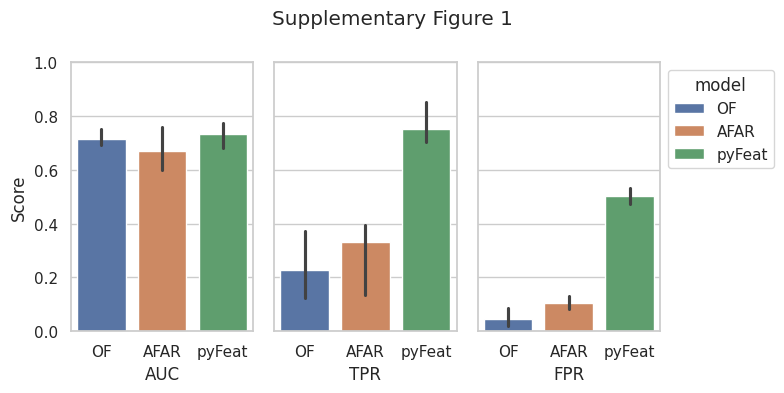

In [10]:
DVs=['AUC','TPR', 'FPR']
#sns.set_style(rc = {'axes.facecolor': 'white'})
sns.set(rc={'axes.facecolor':'white', 'figure.facecolor':'white'})
sns.set_style("whitegrid")

fig, axs = plt.subplots(1, len(DVs), sharex=False, sharey=True, figsize=(8, 4))
for DV in range(len(DVs)):
  if DV == len(DVs)-1:
    ax = sns.barplot(df_three, x="model", y=DVs[DV], hue="model", estimator="median", errorbar="ci", ax=axs[DV], legend=True)
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
  else:
    ax = sns.barplot(df_three, x="model", y=DVs[DV], hue="model", estimator="median", errorbar="ci", ax=axs[DV], legend=None)
  axs[DV].set_ylim(0, 1)
  axs[DV].set_xlabel(f'{DVs[DV]}')
  axs[DV].set_ylabel(f'Score')
plt.suptitle(f"Supplementary Figure 1")
plt.subplots_adjust(right=0.7)
plt.tight_layout()
plt.savefig(os.path.join(results_path, "suppl-fig-1.svg"))
plt.show()

In [11]:
df_three[df_three["model"] == "pyFeat"][DVs].describe()

,AUC,TPR,FPR
count,72.000000,72.000000,72.000000
mean,0.662890,0.689103,0.519063
std,0.245200,0.330959,0.105728
min,0.012966,0.000000,0.304700
25%,0.598206,0.606286,0.437894
50%,0.733387,0.751677,0.500810
75%,0.815287,1.000000,0.587520
max,0.997776,1.000000,0.783626


## Results: Binary Classification Performance

In [14]:
DVs=['AUC','TPR', 'FPR']
df_comb[DVs].describe().applymap('{:,.2f}'.format)

/tmp/ipykernel_983047/89499238.py:2: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_comb[DVs].describe().applymap('{:,.2f}'.format)


,AUC,TPR,FPR
count,144.00,144.00,144.00
mean,0.69,0.31,0.10
std,0.20,0.30,0.10
min,0.22,0.00,0.00
25%,0.56,0.00,0.01
50%,0.70,0.27,0.08
75%,0.82,0.51,0.13
max,1.00,1.00,0.50


### Check normality assumption for significance tests

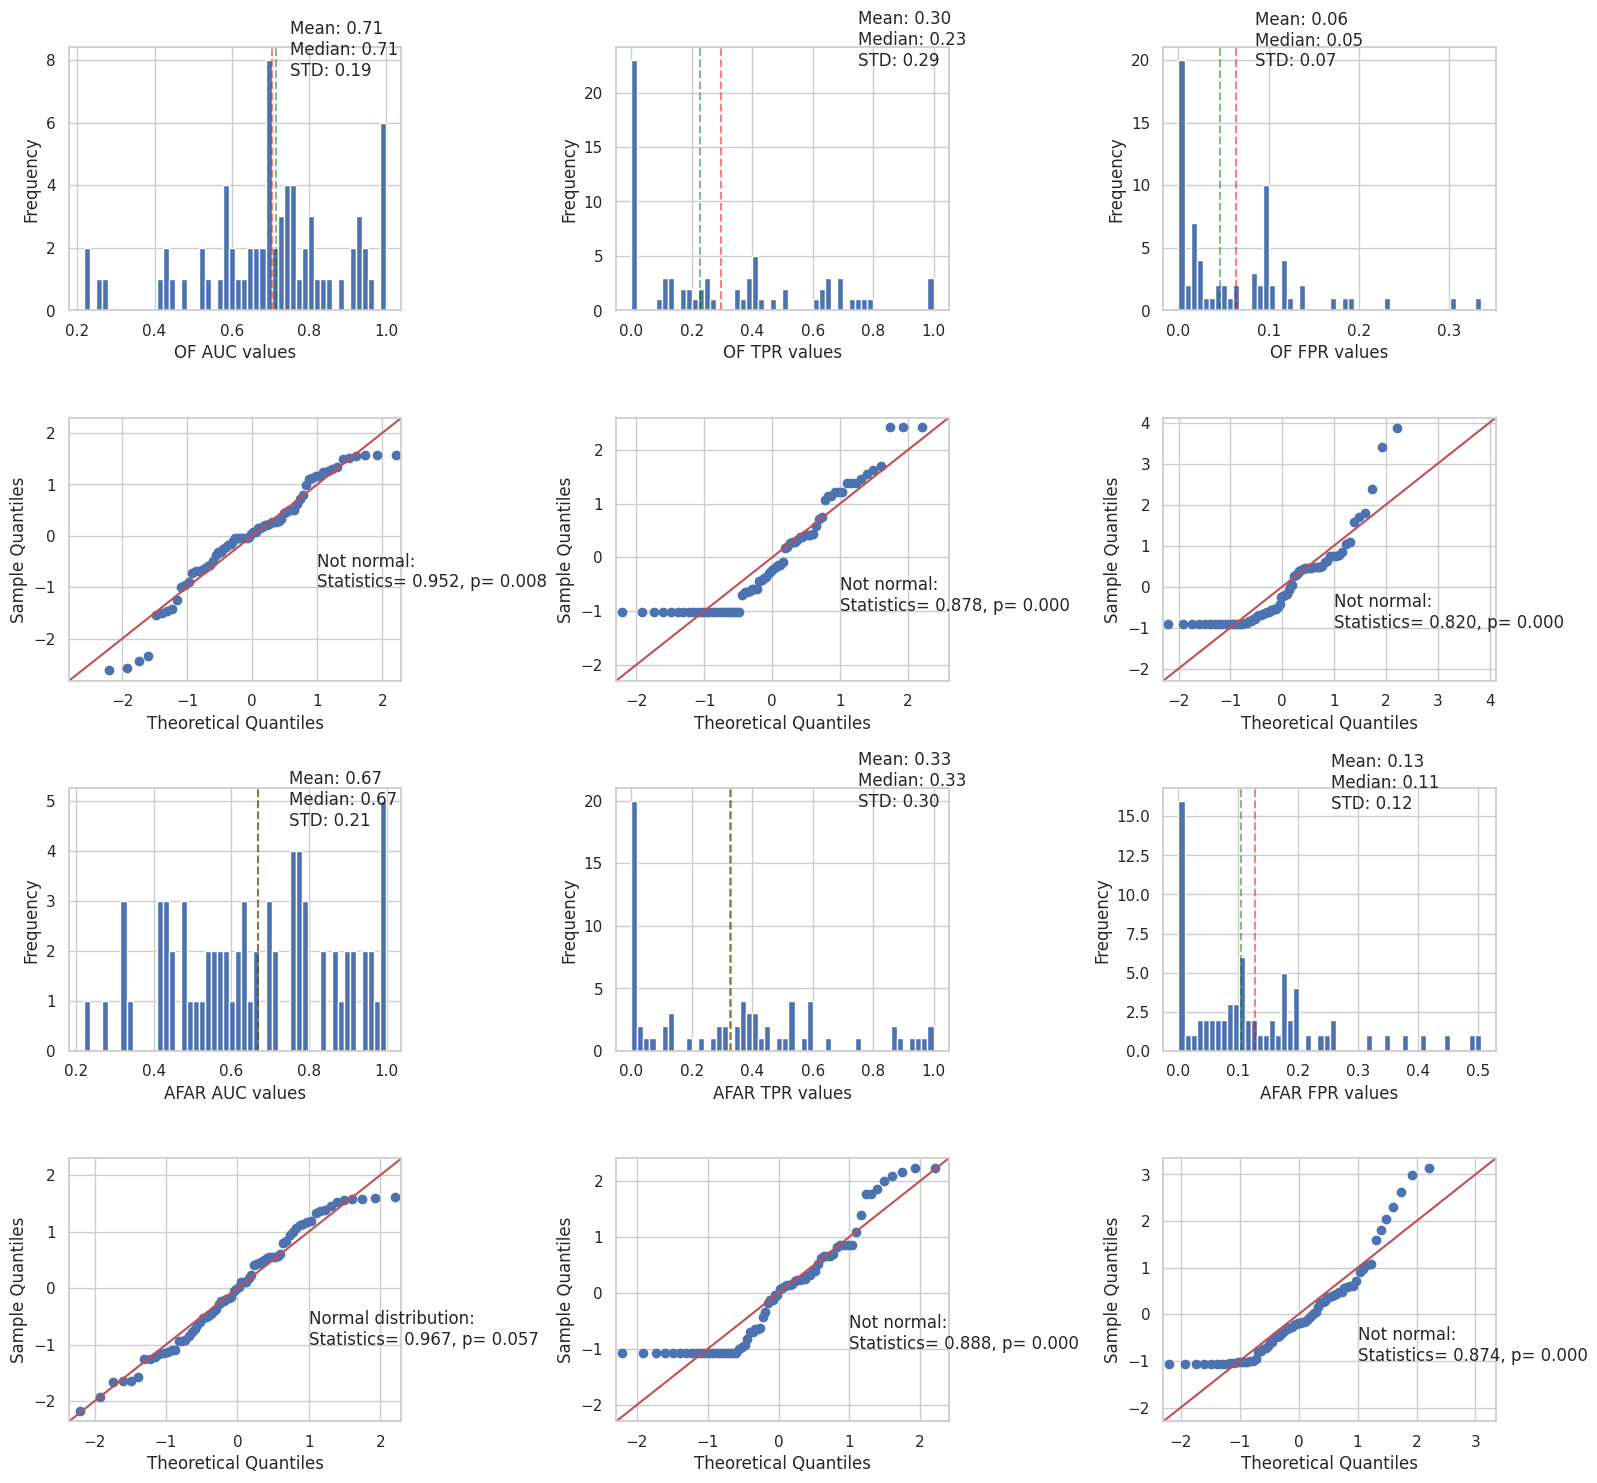

In [12]:
DVs=['AUC', 'TPR', 'FPR']
fig, axs = plt.subplots(4, len(DVs), sharex=False, sharey=False, figsize=(16, 15))

for DV in range(len(DVs)):
  OF_arr = df_OF_all[DVs[DV]].to_numpy()
  hist_OF, bins_OF = np.histogram(OF_arr, bins=50)
  axs[0,DV].hist(OF_arr, bins=50)
  axs[0,DV].set_xlabel(f"OF {DVs[DV]} values")
  axs[0,DV].set_ylabel('Frequency')
  axs[0,DV].axvline(np.mean(OF_arr), linestyle="dashed", color='red', alpha=0.5)
  axs[0,DV].axvline(np.median(OF_arr), linestyle="dashed", color='green', alpha=0.5)
  axs[0,DV].annotate(f'Mean: {np.mean(OF_arr):.2f}\nMedian: {np.median(OF_arr):.2f}\nSTD: {np.std(OF_arr):.2f}',
                xy=(max(bins_OF) - 0.25, max(hist_OF) - 0.5),
                xytext=(max(bins_OF) - 0.25, max(hist_OF) - 0.5))
  # Standardize the data
  std_arr = []
  for i in range(len(OF_arr)):
      std_arr.append((OF_arr[i]-np.mean(OF_arr))/np.std(OF_arr))

  sm.qqplot(np.array(std_arr), line ='45', ax=axs[1,DV])
  stat, p = shapiro(OF_arr)
  alpha = 0.05
  if p > alpha:
    axs[1,DV].annotate(f'Normal distribution:\nStatistics= {stat:.3f}, p= {p:.3f}',
                xy=(1, -1),
                xytext=(1, -1))
  else:
    axs[1,DV].annotate(f'Not normal:\nStatistics= {stat:.3f}, p= {p:.3f}',
                xy=(1, -1),
                xytext=(1, -1))


  AFAR_arr = df_AFAR_all[DVs[DV]].to_numpy()
  hist_AFAR, bins_AFAR = np.histogram(AFAR_arr, bins=50)
  axs[2,DV].hist(AFAR_arr, bins=50)
  axs[2,DV].set_xlabel(f"AFAR {DVs[DV]} values")
  axs[2,DV].set_ylabel('Frequency')
  axs[2,DV].axvline(np.mean(AFAR_arr), linestyle="dashed", color='red', alpha=0.5)
  axs[2,DV].axvline(np.median(AFAR_arr), linestyle="dashed", color='green', alpha=0.5)
  axs[2,DV].annotate(f'Mean: {np.mean(AFAR_arr):.2f}\nMedian: {np.median(AFAR_arr):.2f}\nSTD: {np.std(AFAR_arr):.2f}',
                xy=(max(bins_AFAR) - 0.25, max(hist_AFAR) - 0.5),
                xytext=(max(bins_AFAR) - 0.25, max(hist_AFAR) - 0.5))
  # Standardize the data
  std_arr = []
  for i in range(len(AFAR_arr)):
      std_arr.append((AFAR_arr[i]-np.mean(AFAR_arr))/np.std(AFAR_arr))

  sm.qqplot(np.array(std_arr), line ='45', ax = axs[3,DV])
  stat, p = shapiro(AFAR_arr)
  alpha = 0.05
  if p > alpha:
    axs[3,DV].annotate(f'Normal distribution:\nStatistics= {stat:.3f}, p= {p:.3f}',
                xy=(1, -1),
                xytext=(1, -1))
  else:
    axs[3,DV].annotate(f'Not normal:\nStatistics= {stat:.3f}, p= {p:.3f}',
                xy=(1, -1),
                xytext=(1, -1))


plt.tight_layout()
plt.show()

In [13]:
# CHECK FURTHER ANOVA ASSUMPTIONS OTHER THAN NORMALITY FOR AUC:
pg.homoscedasticity([df_OF_all['AUC'].to_numpy(),
                     df_AFAR_all['AUC'].to_numpy(),
                     df_pyFEAT_all['AUC'].to_numpy()])  # there should be equal variance

,W,pval,equal_var
levene,1.563848,0.211723,True


### AUC: Greater than chance?

In [15]:
# independent t-test to compare AUC scores
chance_level = 0.50
pg.ttest(df_comb['AUC'].values, chance_level)

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,11.294837,143,two-sided,1.519248e-21,"[0.65, 0.72]",0.941236,2.983e+18,1.0


### AUC: Between Model Comparisons

In [27]:
factors=['avatar','animation','AUC', 'model']
df_comb[factors].groupby('model').describe().applymap('{:,.2f}'.format)

/tmp/ipykernel_983047/2120417716.py:2: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_comb[factors].groupby('model').describe().applymap('{:,.2f}'.format)


AUC                                          
       count  mean   std   min   25%   50%   75%   max
model                                                 
AFAR   72.00  0.67  0.21  0.22  0.50  0.67  0.83  1.00
OF     72.00  0.71  0.19  0.22  0.60  0.71  0.81  1.00

In [19]:
# Paired t-test to compare AUC scores
pg.ttest(df_comb[df_comb['model'] == 'OF']['AUC'].values, df_comb[df_comb['model'] == 'AFAR']['AUC'].values, paired= True)

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,1.391985,71,two-sided,0.168272,"[-0.02, 0.09]",0.185714,0.326,0.342802


### AUC: Within Factor Comparisons

In [16]:
# ANOVA wn "subjects"
aov = pg.rm_anova(dv='AUC', within='avatar',
                  subject='model', data=df_comb, detailed=True, effsize="np2")

aov.round(3)

,Source,SS,DF,MS,F,p-unc,np2,eps
0,avatar,0.001,3,0.0,0.975,0.508,0.494,0.333
1,Error,0.001,3,0.0,NaN,NaN,NaN,NaN


In [17]:
# ANOVA wn "subjects"
aov = pg.rm_anova(dv='AUC', within='animation',
                  subject='model', data=df_comb, detailed=True, effsize="np2")

aov.round(3)

,Source,SS,DF,MS,F,p-unc,p-GG-corr,np2,eps,sphericity,W-spher,p-spher
0,animation,0.69,17,0.041,2.303,0.047,0.371,0.697,0.059,False,1.960851e+29,0.0
1,Error,0.30,17,0.018,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [21]:
df_comb

,avatar,animation,TP,FP,TN,FN,false_detections,TP_perc,FP_perc,TN_perc,FN_perc,TPR,FPR,F1_score,AUC,model
0,Ada,AU01,4,0,617,39,[],1,0,93,6,0.093023,0.000000,0.170213,0.759376,OF
1,Ada,AU02,0,0,617,43,[],0,0,93,7,0.000000,0.000000,0.000000,0.578210,OF
2,Ada,AU04,0,1,616,43,['AU01'],0,0,93,7,0.000000,0.001621,0.000000,0.415947,OF
3,Ada,AU06,0,21,596,43,"['AU07', 'AU07', 'AU07', 'AU07', 'AU07', 'AU07...",0,3,90,7,0.000000,0.034036,0.000000,0.250405,OF
4,Ada,AU07,27,0,617,16,[],4,0,93,2,0.627907,0.000000,0.771429,0.986544,OF
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,Pia,browsAU12,57,208,305,90,"['AU07', 'AU07', 'AU14', 'AU23', 'AU07', 'AU14...",9,32,46,14,0.387755,0.405458,0.276699,0.429062,AFAR
140,Pia,browsAU14,54,54,459,93,"['AU23', 'AU07', 'AU23', 'AU07', 'AU23', 'AU07...",8,8,70,14,0.367347,0.105263,0.423529,0.564838,AFAR
141,Pia,browsAU15,17,0,513,130,[],3,0,78,20,0.115646,0.000000,0.207317,0.691809,AFAR
142,Pia,browsAU17,19,3,514,124,"['AU23', 'AU23', 'AU23']",3,0,78,19,0.132867,0.005803,0.230303,0.557506,AFAR


In [24]:
df_comb.groupby(["model","animation"])[["TPR","FPR"]].describe()

TPR                                                    \
                count      mean       std       min       25%       50%   
model animation                                                           
AFAR  AU01        4.0  0.476744  0.326963  0.000000  0.436047  0.581395   
      AU02        4.0  0.104651  0.209302  0.000000  0.000000  0.000000   
      AU04        4.0  0.470930  0.545851  0.000000  0.000000  0.441860   
      AU06        4.0  0.000000  0.000000  0.000000  0.000000  0.000000   
      AU07        4.0  0.122093  0.214303  0.000000  0.000000  0.023256   
      AU10        4.0  0.145349  0.290698  0.000000  0.000000  0.000000   
      AU12        4.0  0.360465  0.238301  0.023256  0.302326  0.418605   
      AU14        4.0  0.674419  0.281642  0.348837  0.488372  0.697674   
      AU15        4.0  0.459302  0.532477  0.000000  0.000000  0.430233   
      AU17        4.0  0.142857  0.285714  0.000000  0.000000  0.000000   
      AU23        4.0  0.703488  0.308742  0.372093  0.476744  0.720930   
      browsAU10   4.0  0.260204  0.108613  0.136054  0.202381  0.255102   
      browsAU12   4.0  0.420068  0.070559  0.367347  0.382653  0.394558   
      browsAU14   4.0  0.462585  0.140407  0.346939  0.362245  0.425170   
      browsAU15   4.0  0.273810  0.235874  0.034014  0.095238  0.268707   
      browsAU17   4.0  0.215035  0.132974  0.076923  0.118881  0.209790   
      browsAU23   4.0  0.331633  0.169603  0.129252  0.236395  0.336735   
      browsAll    4.0  0.234375  0.096413  0.114583  0.177083  0.255208   
OF    AU01        4.0  0.180233  0.165944  0.000000  0.069767  0.174419   
      AU02        4.0  0.000000  0.000000  0.000000  0.000000  0.000000   
      AU04        4.0  0.383721  0.443489  0.000000  0.000000  0.372093   
      AU06        4.0  0.000000  0.000000  0.000000  0.000000  0.000000   
      AU07        4.0  0.906977  0.186047  0.627907  0.906977  1.000000   
      AU10        4.0  0.598837  0.261305  0.209302  0.575581  0.709302   
      AU12        4.0  0.627907  0.080561  0.511628  0.616279  0.651163   
      AU14        4.0  0.645349  0.039717  0.604651  0.622093  0.639535   
      AU15        4.0  0.000000  0.000000  0.000000  0.000000  0.000000   
      AU17        4.0  0.000000  0.000000  0.000000  0.000000  0.000000   
      AU23        4.0  0.000000  0.000000  0.000000  0.000000  0.000000   
      browsAU10   4.0  0.433673  0.064387  0.353741  0.399660  0.438776   
      browsAU12   4.0  0.399660  0.021779  0.380952  0.380952  0.397959   
      browsAU14   4.0  0.404762  0.011783  0.387755  0.403061  0.408163   
      browsAU15   4.0  0.181973  0.076839  0.108844  0.119048  0.183673   
      browsAU17   4.0  0.160839  0.053866  0.111888  0.122378  0.150350   
      browsAU23   4.0  0.159864  0.053995  0.108844  0.119048  0.153061   
      browsAll    4.0  0.242187  0.081301  0.166667  0.182292  0.229167   

                                      FPR                                \
                      75%       max count      mean       std       min   
model animation                                                           
AFAR  AU01       0.622093  0.744186   4.0  0.114668  0.134417  0.000000   
      AU02       0.104651  0.418605   4.0  0.066045  0.048521  0.001621   
      AU04       0.912791  1.000000   4.0  0.035251  0.050432  0.000000   
      AU06       0.000000  0.000000   4.0  0.101297  0.110453  0.003241   
      AU07       0.145349  0.441860   4.0  0.082253  0.074241  0.000000   
      AU10       0.145349  0.581395   4.0  0.126418  0.045918  0.071313   
      AU12       0.476744  0.581395   4.0  0.284036  0.093183  0.171799   
      AU14       0.883721  0.953488   4.0  0.129660  0.084372  0.029173   
      AU15       0.889535  0.976744   4.0  0.085900  0.076364  0.000000   
      AU17       0.142857  0.571429   4.0  0.094000  0.087376  0.004800   
      AU23       0.947674  1.000000   4.0  0.044571  0.061595  0.000000   
      browsAU10  0.312925  0.394558   4.0 

### TPR and FPR: Between Model Comparisons

In [26]:
factors=['avatar','animation','TPR','FPR', 'model']
df_comb[factors].groupby('model').describe().applymap('{:,.2f}'.format)
#df_comb.columns

/tmp/ipykernel_983047/2693473562.py:2: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_comb[factors].groupby('model').describe().applymap('{:,.2f}'.format)


TPR                                              FPR              \
       count  mean   std   min   25%   50%   75%   max  count  mean   std   
model                                                                       
AFAR   72.00  0.33  0.30  0.00  0.00  0.33  0.52  1.00  72.00  0.13  0.12   
OF     72.00  0.30  0.29  0.00  0.00  0.23  0.47  1.00  72.00  0.06  0.07   

                                     
        min   25%   50%   75%   max  
model                                
AFAR   0.00  0.03  0.11  0.18  0.50  
OF     0.00  0.00  0.05  0.10  0.34

In [28]:
DVs=['TPR', 'FPR']
# Perform Wilcoxon Signed-Rank Test
print(f"Wilcoxon Signed-Rank Test for threshold: {threshold}")
for DV in DVs:
    # Split data by avatar and model
    scores_OF = df_comb[df_comb['model'] == 'OF'][DV].values
    scores_AFAR = df_comb[df_comb['model'] == 'AFAR'][DV].values

    # Perform Wilcoxon Signed-Rank Test
    wilcoxon_results = pg.wilcoxon(scores_OF, scores_AFAR)
    print(f"Wilcoxon Signed-Rank Test for {DV}:")
    print(wilcoxon_results)

Wilcoxon Signed-Rank Test for threshold: 0.2
Wilcoxon Signed-Rank Test for TPR:
          W-val alternative     p-val       RBC      CLES
Wilcoxon  752.0   two-sided  0.425174 -0.120982  0.471644
Wilcoxon Signed-Rank Test for FPR:
          W-val alternative         p-val      RBC      CLES
Wilcoxon  304.5   two-sided  4.100765e-08 -0.75493  0.330633


### TPR and FPR: Within Factor Comparisons

In [11]:
DVs=['TPR', 'FPR']
for DV in DVs:
    friedman_results = pg.friedman(data=df_comb, dv=DV, within='avatar', subject='animation')
    print(f"Friedman's test for {DV} results:")
    print(friedman_results) # Outputs the test stat, p-value, and Kendall's W
    print(f"Less than the corrected p-val (p/N)? = {friedman_results['p-unc'].values[0] < (0.05 / len(df_comb['avatar'].unique()))}")

Friedman's test for TPR results:
          Source         W  ddof1          Q     p-unc
Friedman  avatar  0.378407      3  20.433962  0.000138
Less than the corrected p-val (p/N)? = True
Friedman's test for FPR results:
          Source        W  ddof1          Q         p-unc
Friedman  avatar  0.79671      3  43.022346  2.434263e-09
Less than the corrected p-val (p/N)? = True


In [33]:
DVs=['TPR', 'FPR']
for DV in DVs:
    friedman_results = pg.friedman(data=df_comb, dv=DV, within='animation', subject='avatar')
    print(f"Friedman's test for {DV} results:")
    print(friedman_results) # Outputs the test stat, p-value, and Kendall's W
    print(f"Less than the corrected p-val (p/N)? = {friedman_results['p-unc'].values[0] < (0.05 / len(df_comb['animation'].unique()))}")

Friedman's test for TPR results:
             Source         W  ddof1         Q    p-unc
Friedman  animation  0.658883     17  44.80407  0.00026
Less than the corrected p-val (p/N)? = True
Friedman's test for FPR results:
             Source         W  ddof1          Q     p-unc
Friedman  animation  0.757484     17  51.508903  0.000025
Less than the corrected p-val (p/N)? = True


### Figure 2: AUC heatmaps, TPR and FPR across avatars and animations

In [35]:
sns.reset_defaults()

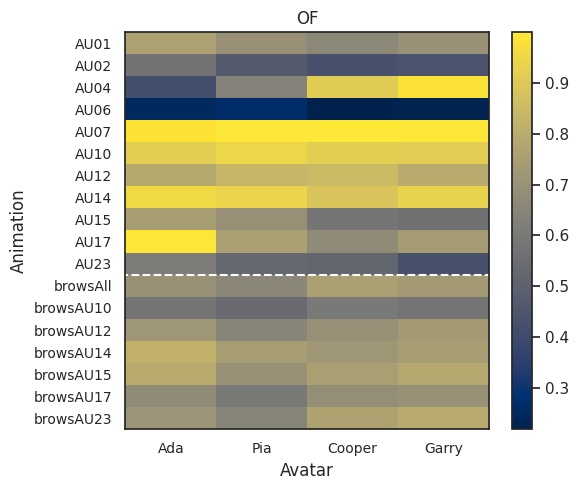

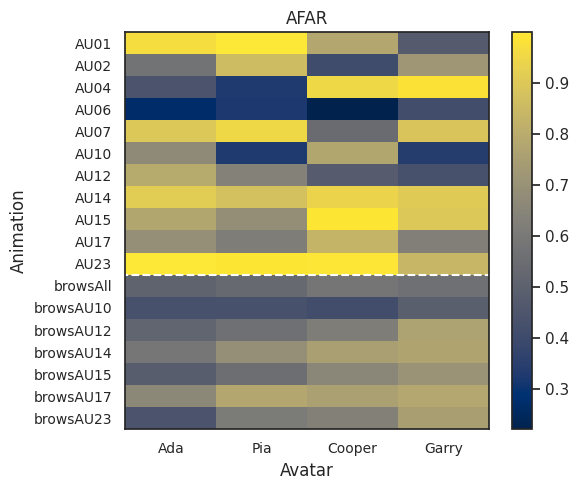

In [55]:
import matplotlib as mpl

sns.set(rc={'axes.facecolor':'white', 'figure.facecolor':'white'})
sns.set_style('white')
# Manuscript styling
mpl.rcParams['font.size'] = 10
label_fontsize = 12
tick_fontsize = 10
dpi_val = 500
bar_order = ['Ada', 'Pia', 'Cooper', 'Garry']
for model in ['OF', 'AFAR']:
    df_model = df_comb[df_comb['model'] == model]
    heatmap = df_model.pivot_table(values='AUC', index='animation', columns='avatar')
    new_order = ['Ada', 'Pia', 'Cooper', 'Garry']
    heatmap = heatmap[new_order]

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(heatmap, aspect='auto', cmap='cividis')

    ax.set_xticks(range(len(new_order)))
    ax.set_xticklabels(new_order, fontsize=tick_fontsize)
    ax.set_yticks(range(len(animations)))
    ax.set_yticklabels(animations, fontsize=tick_fontsize)

    ax.set_xlabel("Avatar", fontsize=label_fontsize)
    ax.set_ylabel("Animation", fontsize=label_fontsize)
    ax.set_title(f"{model}", fontsize=label_fontsize)

    fig.colorbar(im, ax=ax)
    #im.set_clim(0, 1)
    ax.axhline(y=10.5, xmin=-1, color= "white", ls="--")

    fig.tight_layout()
    fig.savefig(f"{results_path}/Figure2A_AUC-heatmap-{model}.svg", dpi=dpi_val)
    plt.show(fig)



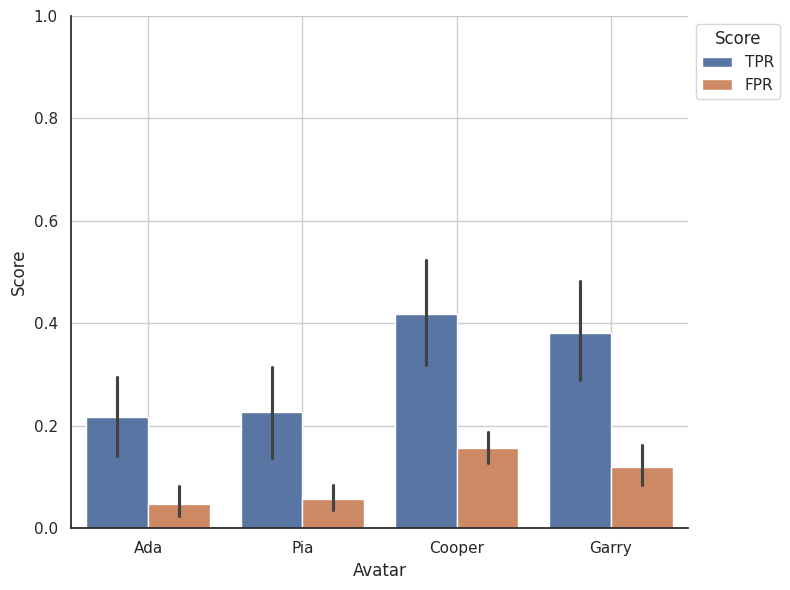

In [57]:
import matplotlib as mpl

df_tpr_fpr = df_comb[["avatar","animation","TPR","FPR"]]
df = pd.melt(df_tpr_fpr, id_vars=['avatar','animation'], var_name="Score")

sns.set(rc={'axes.facecolor':'white', 'figure.facecolor':'white'})
sns.set_style('white')

# Manuscript styling
mpl.rcParams['font.size'] = 10
label_fontsize = 12
tick_fontsize = 10
dpi_val = 500
bar_order = ['Ada', 'Pia', 'Cooper', 'Garry']

fig, axs = plt.subplots(figsize=(8, 6))
#ax = sns.boxplot(df, x="avatar", y="value", ax=axs[DV])
ax = sns.barplot(df, x="avatar", y="value", hue="Score", order = bar_order, ax= axs, legend=True)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
sns.despine()
axs.set_ylim(0, 1)
axs.set_xlabel(f'Avatar')
axs.set_ylabel(f'Score')
plt.grid()
plt.subplots_adjust(right=0.7)
plt.tight_layout()
fig.savefig(f"{results_path}/Figure2B_TPR_FPR_mean-barplot-CI_thr-{threshold}_with-grid.svg", dpi=dpi_val)
plt.show()

/tmp/ipykernel_983047/3724150158.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[DV].set_xticklabels(animations, fontsize=tick_fontsize)
/tmp/ipykernel_983047/3724150158.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[DV].set_xticklabels(animations, fontsize=tick_fontsize)


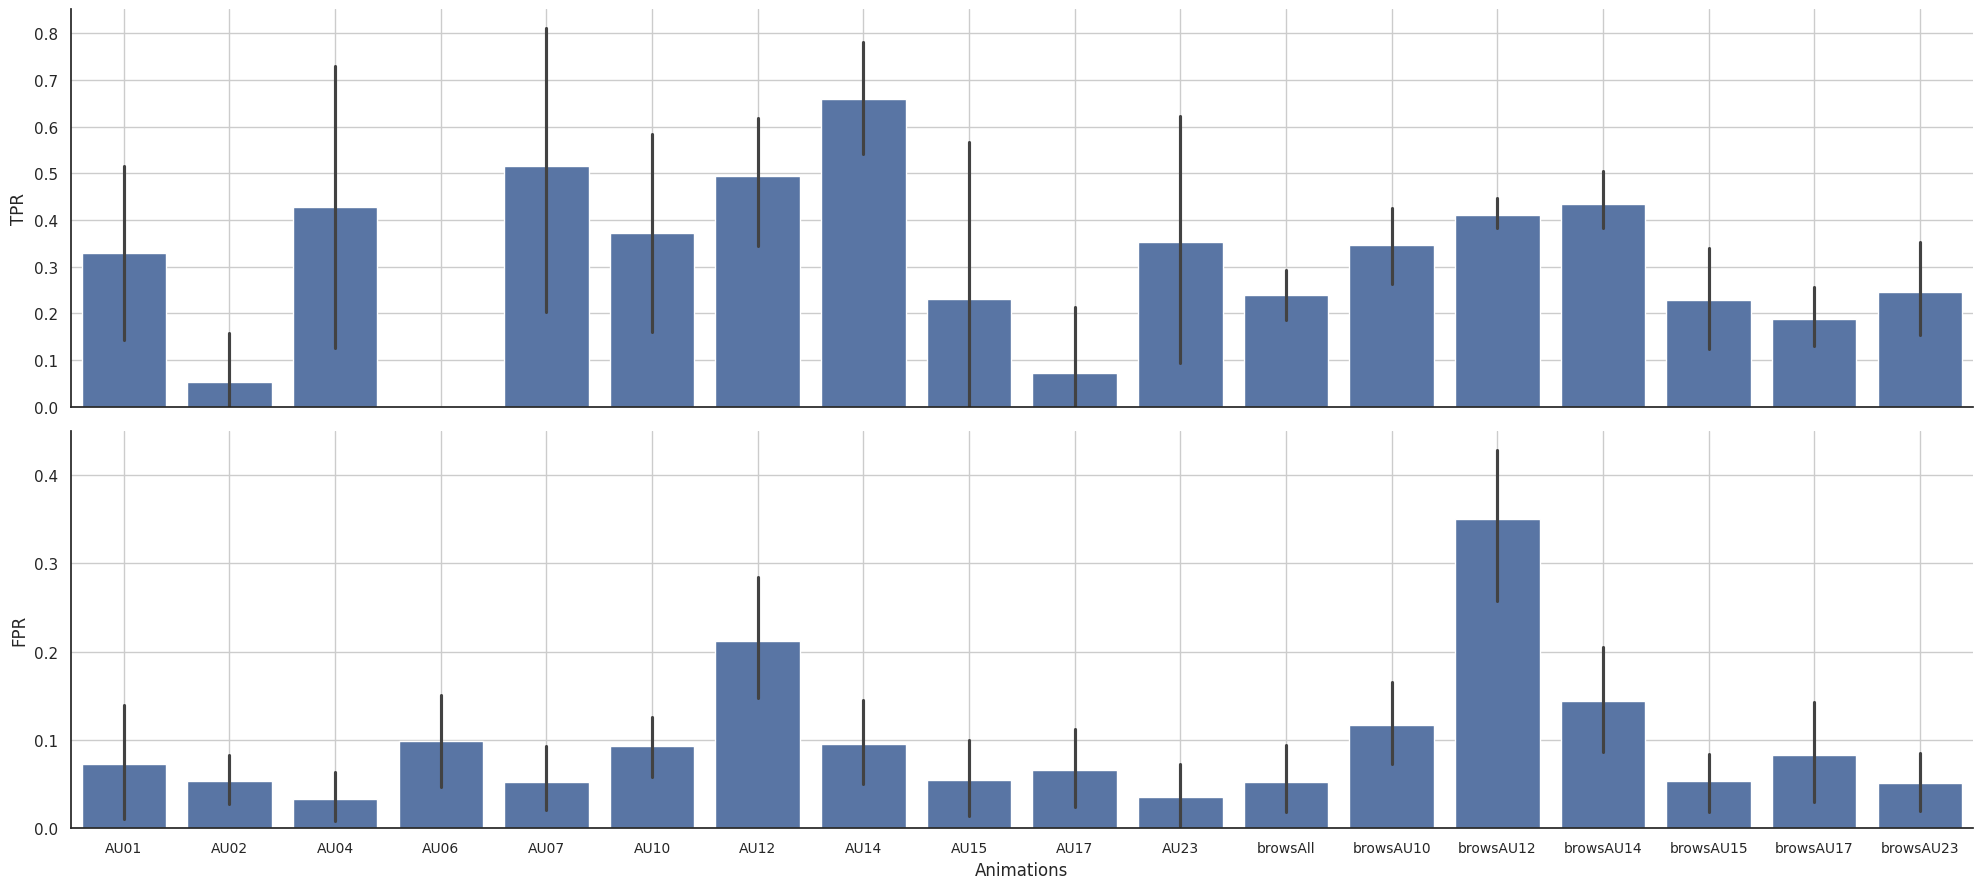

In [60]:
DVs=['TPR', 'FPR']
sns.set_style("white")

fig, axs = plt.subplots(len(DVs), 1, sharex=True, sharey=False, figsize=(20, 9))
for DV in range(len(DVs)):
  ax = sns.barplot(df_comb, x="animation", y=DVs[DV], ax=axs[DV])
  sns.despine()
  #axs[DV].set_ylim(0, 1)
  axs[DV].set_xlabel(f'Animations', fontsize=label_fontsize)
  axs[DV].set_ylabel(f'{DVs[DV]}', fontsize=label_fontsize)
  axs[DV].set_xticklabels(animations, fontsize=tick_fontsize)
  axs[DV].grid()
plt.subplots_adjust(right=0.7)
plt.tight_layout()
fig.savefig(f"{results_path}/Figure2C_TPR_FPR_barplot_mean_ci_grid.svg", dpi=dpi_val)
plt.show()

## Results: Temporal Alignment

In [ ]:
from scipy.signal import correlate

cross_corr_df = pd.DataFrame(columns=["Avatar", "Animation", "crosscorr_0_act-OF", "crosscorr_0_act-AFAR"]); row=-1
for av in avatars:
    for anim in animations:
        row +=1; cross_corr_df.loc[row,"Avatar"] = av; cross_corr_df.loc[row,"Animation"] = anim

        actual_mat = loadmat(os.path.join(data_path, f"{av}_actualValues_anim_{anim}.mat"))
        actual_data = actual_mat['actual_mat']; actual_data = actual_data.T
        AFAR_pred_mat = loadmat(os.path.join(data_path, f"{av}_AFARpred_anim_{anim}.mat"))
        AFAR_pred = AFAR_pred_mat['AFAR_pred']; AFAR_pred = AFAR_pred.T
        OF_pred_mat = loadmat(os.path.join(data_path, f"{av}_OFpred_anim_{anim}.mat"))
        OF_pred = OF_pred_mat['normed_OF_pred']; OF_pred = OF_pred.T

        # Compute cross-correlation - OF
        correlation = correlate((actual_data.flatten() - np.mean(actual_data.flatten()) ), (OF_pred.flatten() - np.mean(OF_pred.flatten())), mode="full")
        correlation = correlation / (len(actual_data.flatten()) * actual_data.flatten().std() * OF_pred.flatten().std())

        # Get lags
        lags = signal.correlation_lags(len(actual_data.flatten()), len(OF_pred.flatten()), mode="full")

        # Restrict to max_lag
        max_lag = len(actual_data.flatten()) // 4 
        mask = np.abs(lags) <= max_lag
        correlation = correlation[mask]
        lags = lags[mask]
        cross_corr_0 = correlation[lags == 0]
        cross_corr_df.loc[row,"crosscorr_0_act-OF"] = cross_corr_0; cross_corr_0 = None

        # Compute cross-correlation - AFAR
        correlation = correlate((actual_data.flatten() - np.mean(actual_data.flatten())), (AFAR_pred.flatten() - np.mean(AFAR_pred.flatten())), mode="full")
        correlation = correlation / (len(actual_data.flatten()) * actual_data.flatten().std() * AFAR_pred.flatten().std())

        # Get lags
        lags = signal.correlation_lags(len(actual_data.flatten()), len(AFAR_pred.flatten()), mode="full")

        # Restrict to max_lag
        max_lag = len(actual_data.flatten()) // 4 
        mask = np.abs(lags) <= max_lag
        correlation = correlation[mask]
        lags = lags[mask]
        cross_corr_0 = correlation[lags == 0]
        cross_corr_df.loc[row,"crosscorr_0_act-AFAR"] = cross_corr_0; cross_corr_0 = None      
print(cross_corr_df)

   Avatar  Animation    crosscorr_0_act-OF  crosscorr_0_act-AFAR
0     Ada       AU01    0.8169722042834051    0.8983009621079568
1     Ada       AU02   0.09010360044088059  -0.10273364469679497
2     Ada       AU04   -0.0812407055795056  -0.08184584510005341
3     Ada       AU06  -0.10890563040934463  -0.09563548909937646
4     Ada       AU07     0.908708449346705   0.15803741622880527
..    ...        ...                   ...                   ...
67    Pia  browsAU12   0.24335083303054253   0.06362920134789615
68    Pia  browsAU14    0.4613979155634017    0.3299295818403769
69    Pia  browsAU15    0.3149712339878964    0.3159606898110919
70    Pia  browsAU17    0.3070701709405839   0.34957501560665094
71    Pia  browsAU23   0.21609894379062883    0.4304157200718598

[72 rows x 4 columns]


In [62]:
numeric_cols = ["crosscorr_0_act-OF", "crosscorr_0_act-AFAR"]

for col in numeric_cols:
    cross_corr_df[col] =  cross_corr_df[col].astype('float')

cat_columns = ["Avatar", "Animation"]
for col in cat_columns:
    cross_corr_df[col] = cross_corr_df[col].astype('category')

cross_corr_df.groupby("Animation")[["crosscorr_0_act-OF", "crosscorr_0_act-AFAR"]].describe()

/tmp/ipykernel_983047/3406367127.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cross_corr_df.groupby("Animation")[["crosscorr_0_act-OF", "crosscorr_0_act-AFAR"]].describe()


crosscorr_0_act-OF                                          \
                       count      mean       std       min       25%   
Animation                                                              
AU01                     4.0  0.489699  0.267165  0.244796  0.286779   
AU02                     4.0 -0.004488  0.073545 -0.070961 -0.057981   
AU04                     4.0  0.250224  0.357066 -0.081241 -0.042908   
AU06                     4.0 -0.116317  0.019726 -0.140686 -0.126318   
AU07                     4.0  0.876190  0.051932  0.800538  0.863115   
AU10                     4.0  0.623853  0.116049  0.511393  0.531870   
AU12                     4.0  0.454117  0.032130  0.429785  0.432361   
AU14                     4.0  0.612565  0.185413  0.440705  0.511094   
AU15                     4.0  0.188407  0.247171 -0.005554 -0.000953   
AU17                     4.0  0.218994  0.449842 -0.065557  0.001111   
AU23                     4.0  0.003524  0.153057 -0.095179 -0.079870   
browsAU10                4.0  0.527073  0.038703  0.499447  0.502704   
browsAU12                4.0  0.307513  0.045477  0.243351  0.294051   
browsAU14                4.0  0.503993  0.099282  0.412079  0.449068   
browsAU15                4.0  0.379085  0.076980  0.313834  0.314687   
browsAU17                4.0  0.417298  0.105976  0.307070  0.336510   
browsAU23                4.0  0.297580  0.083103  0.216099  0.230892   
browsAll                 4.0  0.443065  0.093246  0.331339  0.387104   

                                        crosscorr_0_act-AFAR            \
                50%       75%       max                count      mean   
Animation                                                                
AU01       0.448513  0.651432  0.816972                  4.0  0.535814   
AU02      -0.018547  0.034946  0.090104                  4.0  0.079265   
AU04       0.233717  0.526849  0.614700                  4.0  0.304650   
AU06      -0.115217 -0.105216 -0.094148                  4.0 -0.129121   
AU07       0.896341  0.909416  0.911538                  4.0  0.223475   
AU10       0.619629  0.711612  0.744763                  4.0  0.058181   
AU12       0.443543  0.465299  0.499595                  4.0  0.116744   
AU14       0.568672  0.670143  0.872212                  4.0  0.504344   
AU15       0.121476  0.310836  0.516231                  4.0  0.305186   
AU17       0.025428  0.243311  0.890678                  4.0 -0.020394   
AU23      -0.060966  0.022428  0.231205                  4.0  0.696844   
browsAU10  0.512777  0.537146  0.583289                  4.0  0.203480   
browsAU12  0.319025  0.332486  0.348650                  4.0  0.030235   
browsAU14  0.480507  0.535432  0.642878                  4.0  0.370903   
browsAU15  0.367957  0.432355  0.466592                  4.0  0.359973   
browsAU17  0.423792  0.504579  0.514537                  4.0  0.201535   
browsAU23  0.301574  0.368261  0.371072                  4.0  0.500427   
browsAll   0.449981  0.505942  0.540957                  4.0  0.330685   

                                                                       
                std       min       25%       50%       75%       max  
Animation                                                              
AU01       0.508472 -0.115036  0.256832  0.639544  0.918527  0.979205  
AU02       0.278996 -0.127523 -0.108931 -0.015814  0.172382  0.476209  
AU04       0.465408 -0.112994 -0.089633  0.294116  0.688400  0.743364  
AU06       0.031584 -0.170497 -0.142510 -0.125176 -0.111788 -0.095635  
AU07       0.347576 -0.102241  0.066526  0.140409  0.297359  0.715323  
AU10       0.288600 -0.135770 -0.101017 -0.058751  0.100447  0.485995  
AU12       0.225773 -0.142164 -0.036052  0.139437  0.292232  0.330266  
AU14       0.118140  0.380571  0.457598  0.485837  0.532583  0.665134  
AU15       0.424108 -0.055669 -0.033065  0.225488  0.563740  0.825438  
AU17       0.132196 -0.100189 -0.088406 -0.079318 -0.011307  0.177249  
AU23  

In [64]:
cross_corr_df.groupby("Avatar")[["crosscorr_0_act-OF", "crosscorr_0_act-AFAR"]].describe()

/tmp/ipykernel_983047/3475069733.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cross_corr_df.groupby("Avatar")[["crosscorr_0_act-OF", "crosscorr_0_act-AFAR"]].describe()


crosscorr_0_act-OF                                                    \
                    count      mean       std       min       25%       50%   
Avatar                                                                        
Ada                  18.0  0.482060  0.311421 -0.108906  0.325045  0.497765   
Cooper               18.0  0.296045  0.271652 -0.121528  0.054790  0.347486   
Garry                18.0  0.360858  0.276135 -0.140686  0.102416  0.466418   
Pia                  18.0  0.299342  0.278511 -0.094148  0.071525  0.303922   

                           crosscorr_0_act-AFAR                                \
             75%       max                count      mean       std       min   
Avatar                                                                          
Ada     0.719292  0.908708                 18.0  0.200869  0.328600 -0.102734   
Cooper  0.483351  0.883974                 18.0  0.321655  0.322732 -0.170497   
Garry   0.531359  0.800538                 18.0  0.239005  0.292959 -0.142164   
Pia     0.459515  0.911538                 18.0  0.276743  0.339582 -0.117172   

                                                
             25%       50%       75%       max  
Avatar                                          
Ada    -0.050436  0.072262  0.324754  0.923722  
Cooper  0.031644  0.372826  0.564232  0.825438  
Garry  -0.071670  0.241366  0.479576  0.743364  
Pia    -0.003241  0.297757  0.417954  0.979205

In [66]:
crosscorr_long_df = pd.melt(cross_corr_df, value_vars=["crosscorr_0_act-OF", "crosscorr_0_act-AFAR"], value_name="Cross-correlation", var_name="comparison")
crosscorr_long_df["Avatar"] = np.tile(cross_corr_df["Avatar"].values,2)
crosscorr_long_df["Animation"] = np.tile(cross_corr_df["Animation"].values,2)
crosscorr_long_df

,comparison,Cross-correlation,Avatar,Animation
0,crosscorr_0_act-OF,0.816972,Ada,AU01
1,crosscorr_0_act-OF,0.090104,Ada,AU02
2,crosscorr_0_act-OF,-0.081241,Ada,AU04
3,crosscorr_0_act-OF,-0.108906,Ada,AU06
4,crosscorr_0_act-OF,0.908708,Ada,AU07
...,...,...,...,...
139,crosscorr_0_act-AFAR,0.063629,Pia,browsAU12
140,crosscorr_0_act-AFAR,0.329930,Pia,browsAU14
141,crosscorr_0_act-AFAR,0.315961,Pia,browsAU15
142,crosscorr_0_act-AFAR,0.349575,Pia,browsAU17


In [4]:
#crosscorr_long_df.to_csv(os.path.join(results_path, "crosscorr_long_df.csv"))
crosscorr_long_df = pd.read_csv(os.path.join(results_path, "crosscorr_long_df.csv"),index_col=0)
crosscorr_long_df

,comparison,Cross-correlation,Avatar,Animation
0,crosscorr_0_act-OF,0.816972,Ada,AU01
1,crosscorr_0_act-OF,0.090104,Ada,AU02
2,crosscorr_0_act-OF,-0.081241,Ada,AU04
3,crosscorr_0_act-OF,-0.108906,Ada,AU06
4,crosscorr_0_act-OF,0.908708,Ada,AU07
...,...,...,...,...
139,crosscorr_0_act-AFAR,0.063629,Pia,browsAU12
140,crosscorr_0_act-AFAR,0.329930,Pia,browsAU14
141,crosscorr_0_act-AFAR,0.315961,Pia,browsAU15
142,crosscorr_0_act-AFAR,0.349575,Pia,browsAU17


### Check normality assumption for significance tests

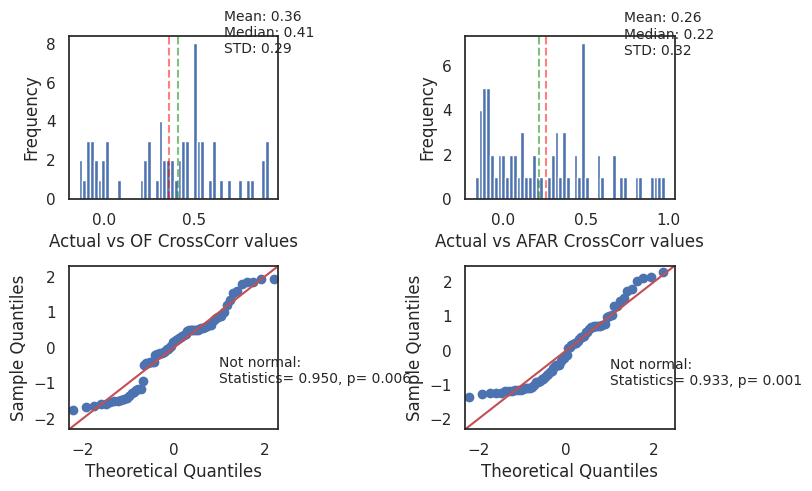

In [73]:
# normal distr?
fig, axs = plt.subplots(2, 2, sharex=False, sharey=False, figsize=(8, 5))

for col, model in enumerate(["OF", "AFAR"]):
  val = f"crosscorr_0_act-{model}"  
  _arr = crosscorr_long_df[crosscorr_long_df["comparison"] == val]["Cross-correlation"].to_numpy()
  hist_, bins_ = np.histogram(_arr, bins=50)
  axs[0,col].hist(_arr, bins=50)
  axs[0,col].set_xlabel(f"Actual vs {model} CrossCorr values")
  axs[0,col].set_ylabel('Frequency')
  axs[0,col].axvline(np.mean(_arr), linestyle="dashed", color='red', alpha=0.5)
  axs[0,col].axvline(np.median(_arr), linestyle="dashed", color='green', alpha=0.5)
  axs[0,col].annotate(f'Mean: {np.mean(_arr):.2f}\nMedian: {np.median(_arr):.2f}\nSTD: {np.std(_arr):.2f}',
                xy=(max(bins_) - 0.25, max(hist_) - 0.5),
                xytext=(max(bins_) - 0.25, max(hist_) - 0.5))
  # Standardize the data
  std_arr = []
  for i in range(len(_arr)):
      std_arr.append((_arr[i]-np.mean(_arr))/np.std(_arr))

  sm.qqplot(np.array(std_arr), line ='45', ax=axs[1,col])
  stat, p = shapiro(_arr)
  alpha = 0.05
  if p > alpha:
    axs[1,col].annotate(f'Normal distribution:\nStatistics= {stat:.3f}, p= {p:.3f}',
                xy=(1, -1),
                xytext=(1, -1))
  else:
    axs[1,col].annotate(f'Not normal:\nStatistics= {stat:.3f}, p= {p:.3f}',
                xy=(1, -1),
                xytext=(1, -1))


plt.tight_layout()
plt.show()

### Between Model Comparison

In [75]:
crosscorr_long_df.groupby("comparison")["Cross-correlation"].describe()

,count,mean,std,min,25%,50%,75%,max
comparison,,,,,,,,
crosscorr_0_act-AFAR,72.0,0.259568,0.317783,-0.170497,-0.029737,0.216349,0.481267,0.979205
crosscorr_0_act-OF,72.0,0.359576,0.288907,-0.140686,0.184600,0.408886,0.517614,0.911538


In [76]:
scores_OF = crosscorr_long_df[crosscorr_long_df['comparison'] == 'crosscorr_0_act-OF']["Cross-correlation"].values
scores_AFAR = crosscorr_long_df[crosscorr_long_df['comparison'] == 'crosscorr_0_act-AFAR']["Cross-correlation"].values

# Perform Wilcoxon Signed-Rank Test
wilcoxon_results = pg.wilcoxon(scores_OF, scores_AFAR)
print(f"Wilcoxon Signed-Rank Test between models' Cross-corr values:")
print(wilcoxon_results)

Wilcoxon Signed-Rank Test between models' Cross-corr values:
          W-val alternative    p-val       RBC      CLES
Wilcoxon  895.0   two-sided  0.01885  0.318874  0.607253


### Within Factor Comparisons

In [81]:
friedman_results = pg.friedman(data=crosscorr_long_df, dv="Cross-correlation", within='Avatar', subject='Animation')
print(f"Friedman's test for cross-corr results:")
print(friedman_results) # Outputs the test stat, p-value, and Kendall's W
print(f"Less than the corrected p-val (p/N)? = {friedman_results['p-unc'].values[0] < (0.05 / len(cross_corr_df['Avatar'].unique()))}")

Friedman's test for cross-corr results:
          Source         W  ddof1         Q     p-unc
Friedman  Avatar  0.065432      3  3.533333  0.316465
Less than the corrected p-val (p/N)? = False


In [84]:
crosscorr_long_df.groupby("Avatar")["Cross-correlation"].describe().sort_values(by="mean",ascending=False)

,count,mean,std,min,25%,50%,75%,max
Avatar,,,,,,,,
Ada,36.0,0.341464,0.346243,-0.108906,0.020572,0.320609,0.579766,0.923722
Cooper,36.0,0.308850,0.294282,-0.170497,-0.001068,0.356757,0.498036,0.883974
Garry,36.0,0.299932,0.287299,-0.142164,0.015892,0.427081,0.512179,0.800538
Pia,36.0,0.288042,0.306297,-0.117172,0.011118,0.303922,0.438250,0.979205


In [82]:
friedman_results = pg.friedman(data=crosscorr_long_df, dv="Cross-correlation", within='Animation', subject='Avatar')
print(f"Friedman's test for cross-corr results:")
print(friedman_results) # Outputs the test stat, p-value, and Kendall's W
print(f"Less than the corrected p-val (p/N)? = {friedman_results['p-unc'].values[0] < (0.05 / len(cross_corr_df['Animation'].unique()))}")


Friedman's test for cross-corr results:
             Source        W  ddof1          Q     p-unc
Friedman  Animation  0.53225     17  36.192982  0.004322
Less than the corrected p-val (p/N)? = False


In [83]:
crosscorr_long_df.groupby("Animation")["Cross-correlation"].describe().sort_values(by="mean",ascending=False)

,count,mean,std,min,25%,50%,75%,max
Animation,,,,,,,,
AU14,8.0,0.558455,0.155117,0.380571,0.472631,0.511478,0.618374,0.872212
AU07,8.0,0.549832,0.417918,-0.102241,0.149223,0.757930,0.890157,0.911538
AU01,8.0,0.512757,0.376832,-0.115036,0.286779,0.488520,0.837304,0.979205
browsAU14,8.0,0.437448,0.108677,0.308219,0.356131,0.436738,0.485353,0.642878
browsAU23,8.0,0.399004,0.127678,0.216099,0.334449,0.400744,0.493746,0.578591
browsAll,8.0,0.386875,0.121876,0.211054,0.303915,0.419369,0.466316,0.540957
browsAU15,8.0,0.369529,0.197359,-0.034739,0.314687,0.368452,0.492463,0.588596
browsAU10,8.0,0.365276,0.195553,0.098872,0.175621,0.447576,0.508283,0.583289
AU23,8.0,0.350184,0.460506,-0.095179,-0.054065,0.175827,0.837162,0.934895


### Within Factor Comparison of OF

In [17]:
df_OF = crosscorr_long_df[crosscorr_long_df["comparison"] == "crosscorr_0_act-OF"]
df_OF = df_OF.reset_index(drop=True)
friedman_results = pg.friedman(data=df_OF, dv="Cross-correlation", within='Avatar', subject='Animation')
print(f"Friedman's test for cross-corr results:")
print(friedman_results) # Outputs the test stat, p-value, and Kendall's W
print(f"Less than the corrected p-val (p/N)? = {friedman_results['p-unc'].values[0] < (0.05 / len(df_OF['Avatar'].unique()))}")

Friedman's test for cross-corr results:
          Source         W  ddof1     Q     p-unc
Friedman  Avatar  0.222222      3  12.0  0.007383
Less than the corrected p-val (p/N)? = True


In [6]:
df_OF.groupby("Avatar")["Cross-correlation"].describe()

,count,mean,std,min,25%,50%,75%,max
Avatar,,,,,,,,
Ada,18.0,0.482060,0.311421,-0.108906,0.325045,0.497765,0.719292,0.908708
Cooper,18.0,0.296045,0.271652,-0.121528,0.054790,0.347486,0.483351,0.883974
Garry,18.0,0.360858,0.276135,-0.140686,0.102416,0.466418,0.531359,0.800538
Pia,18.0,0.299342,0.278511,-0.094148,0.071525,0.303922,0.459515,0.911538


In [87]:
df_OF = crosscorr_long_df[crosscorr_long_df["comparison"] == "crosscorr_0_act-OF"]
df_OF = df_OF.reset_index(drop=True)
friedman_results = pg.friedman(data=df_OF, dv="Cross-correlation", within='Animation', subject='Avatar')
print(f"Friedman's test for cross-corr results:")
print(friedman_results) # Outputs the test stat, p-value, and Kendall's W
print(f"Less than the corrected p-val (p/N)? = {friedman_results['p-unc'].values[0] < (0.05 / len(df_OF['Animation'].unique()))}")

Friedman's test for cross-corr results:
             Source         W  ddof1          Q     p-unc
Friedman  Animation  0.732972     17  49.842105  0.000045
Less than the corrected p-val (p/N)? = True


In [88]:
df_OF.groupby("Animation")["Cross-correlation"].describe()

,count,mean,std,min,25%,50%,75%,max
Animation,,,,,,,,
AU01,4.0,0.489699,0.267165,0.244796,0.286779,0.448513,0.651432,0.816972
AU02,4.0,-0.004488,0.073545,-0.070961,-0.057981,-0.018547,0.034946,0.090104
AU04,4.0,0.250224,0.357066,-0.081241,-0.042908,0.233717,0.526849,0.614700
AU06,4.0,-0.116317,0.019726,-0.140686,-0.126318,-0.115217,-0.105216,-0.094148
AU07,4.0,0.876190,0.051932,0.800538,0.863115,0.896341,0.909416,0.911538
AU10,4.0,0.623853,0.116049,0.511393,0.531870,0.619629,0.711612,0.744763
AU12,4.0,0.454117,0.032130,0.429785,0.432361,0.443543,0.465299,0.499595
AU14,4.0,0.612565,0.185413,0.440705,0.511094,0.568672,0.670143,0.872212
AU15,4.0,0.188407,0.247171,-0.005554,-0.000953,0.121476,0.310836,0.516231


### Within Factor Comparison of AFAR

In [89]:
df_AFAR = crosscorr_long_df[crosscorr_long_df["comparison"] == "crosscorr_0_act-AFAR"]
df_AFAR = df_AFAR.reset_index(drop=True)
friedman_results = pg.friedman(data=df_AFAR, dv="Cross-correlation", within='Avatar', subject='Animation')
print(f"Friedman's test for cross-corr results:")
print(friedman_results) # Outputs the test stat, p-value, and Kendall's W
print(f"Less than the corrected p-val (p/N)? = {friedman_results['p-unc'].values[0] < (0.05 / len(df_AFAR['Avatar'].unique()))}")

Friedman's test for cross-corr results:
          Source         W  ddof1    Q     p-unc
Friedman  Avatar  0.003704      3  0.2  0.977589
Less than the corrected p-val (p/N)? = False


In [90]:
df_AFAR.groupby("Avatar")["Cross-correlation"].describe()

,count,mean,std,min,25%,50%,75%,max
Avatar,,,,,,,,
Ada,18.0,0.200869,0.328600,-0.102734,-0.050436,0.072262,0.324754,0.923722
Cooper,18.0,0.321655,0.322732,-0.170497,0.031644,0.372826,0.564232,0.825438
Garry,18.0,0.239005,0.292959,-0.142164,-0.071670,0.241366,0.479576,0.743364
Pia,18.0,0.276743,0.339582,-0.117172,-0.003241,0.297757,0.417954,0.979205


In [91]:
df_AFAR = crosscorr_long_df[crosscorr_long_df["comparison"] == "crosscorr_0_act-AFAR"]
df_AFAR = df_AFAR.reset_index(drop=True)
friedman_results = pg.friedman(data=df_AFAR, dv="Cross-correlation", within='Animation', subject='Avatar')
print(f"Friedman's test for cross-corr results:")
print(friedman_results) # Outputs the test stat, p-value, and Kendall's W
print(f"Less than the corrected p-val (p/N)? = {friedman_results['p-unc'].values[0] < (0.05 / len(df_AFAR['Animation'].unique()))}")

Friedman's test for cross-corr results:
             Source         W  ddof1          Q     p-unc
Friedman  Animation  0.468266     17  31.842105  0.015742
Less than the corrected p-val (p/N)? = False


In [92]:
df_AFAR.groupby("Animation")["Cross-correlation"].describe().sort_values("mean", ascending=False)

,count,mean,std,min,25%,50%,75%,max
Animation,,,,,,,,
AU23,4.0,0.696844,0.388500,0.120450,0.636344,0.866015,0.926516,0.934895
AU01,4.0,0.535814,0.508472,-0.115036,0.256832,0.639544,0.918527,0.979205
AU14,4.0,0.504344,0.118140,0.380571,0.457598,0.485837,0.532583,0.665134
browsAU23,4.0,0.500427,0.060824,0.430416,0.475959,0.496352,0.520820,0.578591
browsAU14,4.0,0.370903,0.076763,0.308219,0.324502,0.347397,0.393798,0.480598
browsAU15,4.0,0.359973,0.291059,-0.034739,0.228286,0.443018,0.574705,0.588596
browsAll,4.0,0.330685,0.132457,0.211054,0.218996,0.327344,0.439033,0.456999
AU15,4.0,0.305186,0.424108,-0.055669,-0.033065,0.225488,0.563740,0.825438
AU04,4.0,0.304650,0.465408,-0.112994,-0.089633,0.294116,0.688400,0.743364


### Figure 3: Cross-corr heatmaps and barplots across avatars and animations

/tmp/ipykernel_983047/3237043559.py:13: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  heatmap = pd.pivot_table(cross_corr_df, values=val, index='Animation', columns='Avatar')


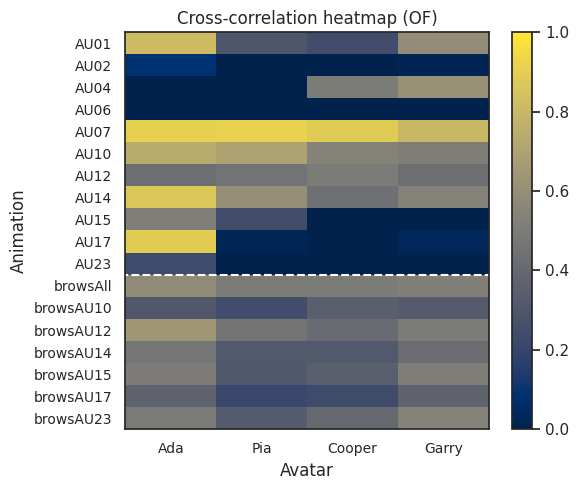

/tmp/ipykernel_983047/3237043559.py:13: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  heatmap = pd.pivot_table(cross_corr_df, values=val, index='Animation', columns='Avatar')


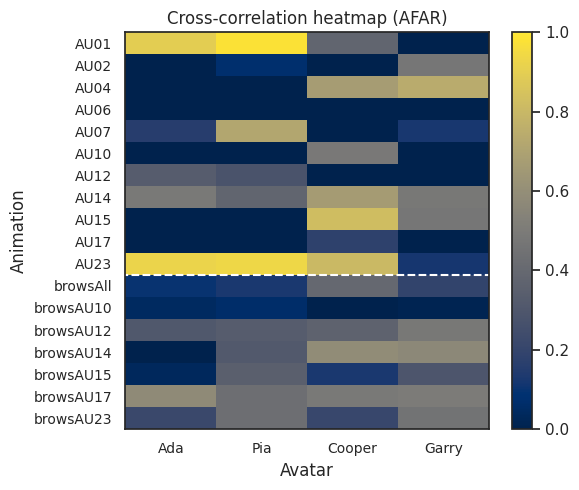

In [ ]:
# Cross-correlation heatmaps

import matplotlib as mpl
mpl.rcParams['font.size'] = 10
label_fontsize = 12
tick_fontsize = 10
dpi_val = 500


for model in ['OF', 'AFAR']:
    val = f"crosscorr_0_act-{model}"
    df_model = cross_corr_df[val]
    heatmap = pd.pivot_table(cross_corr_df, values=val, index='Animation', columns='Avatar')
    new_order = ['Ada', 'Pia', 'Cooper', 'Garry']
    heatmap = heatmap[new_order]

    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(heatmap.values.astype(float), aspect='auto', cmap='cividis')

    ax.set_xticks(range(len(new_order)))
    ax.set_xticklabels(new_order, fontsize=tick_fontsize)
    ax.set_yticks(range(len(animations)))
    ax.set_yticklabels(animations, fontsize=tick_fontsize)

    ax.set_xlabel("Avatar", fontsize=label_fontsize)
    ax.set_ylabel("Animation", fontsize=label_fontsize)
    ax.set_title(f"Cross-correlation heatmap ({model})", fontsize=label_fontsize)
    ax.grid(0)

    fig.colorbar(im, ax=ax)
    im.set_clim(0, 1)
    ax.axhline(y=10.5, xmin=-1, color= "white", ls="--")

    fig.tight_layout()
    fig.savefig(f"{results_path}/Figure3_{model}_CrossCorr_heatmap.svg", dpi=dpi_val)
    plt.show(fig)



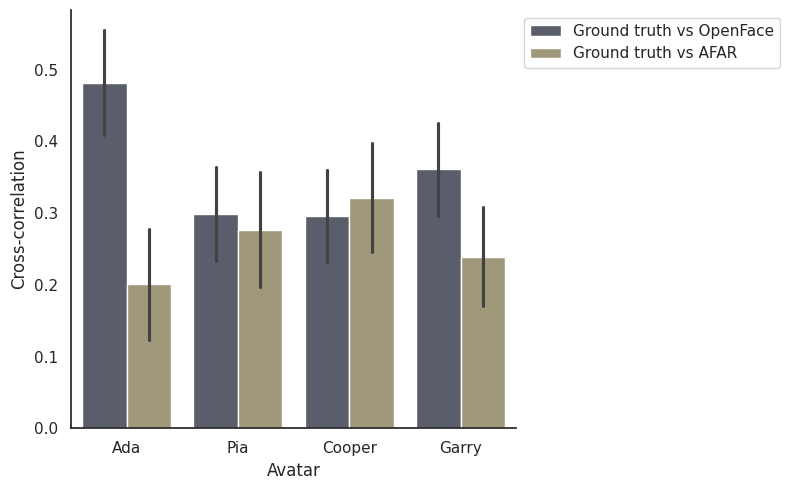

In [ ]:
# Cross-correlation Across Avatars

mpl.rcParams['font.size'] = 10
label_fontsize = 12
tick_fontsize = 10
dpi_val = 500
bar_order = ['Ada', 'Pia', 'Cooper', 'Garry']

fig, ax = plt.subplots(figsize=(8,5))
sns.barplot(crosscorr_long_df, x="Avatar", y='Cross-correlation', hue="comparison", errorbar="se", ax=ax, order=bar_order, palette='cividis')
sns.despine()
ax.set_ylabel("Cross-correlation", fontsize=label_fontsize)
my_map = {'crosscorr_0_act-OF':'Ground truth vs OpenFace', 'crosscorr_0_act-AFAR':'Ground truth vs AFAR'}

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [my_map[l] for l in labels])

sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
fig.savefig(f"{results_path}/Figure3C_barplot_err-se.svg", dpi=dpi_val)
plt.subplots_adjust(right=0.7)
plt.tight_layout()
plt.show()

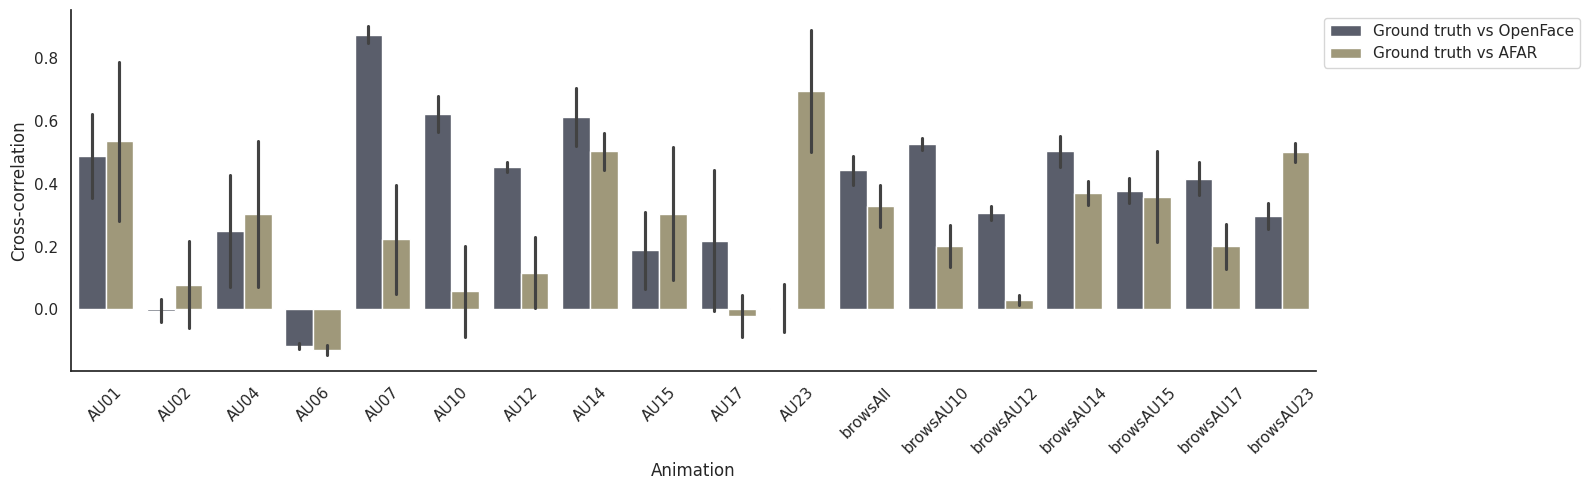

In [70]:
# Cross-correlation Across Animatons

mpl.rcParams['font.size'] = 10
label_fontsize = 12
tick_fontsize = 10
dpi_val = 500

fig, ax = plt.subplots(figsize=(16,5))
sns.barplot(crosscorr_long_df, x="Animation", y='Cross-correlation', hue="comparison", errorbar="se", ax=ax, palette='cividis')
sns.despine()
ax.set_ylabel("Cross-correlation", fontsize=label_fontsize)
my_map = {'crosscorr_0_act-OF':'Ground truth vs OpenFace', 'crosscorr_0_act-AFAR':'Ground truth vs AFAR'}

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [my_map[l] for l in labels])
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.xticks(rotation=45)

fig.savefig(f"{results_path}/Figure3D_barplot_err-se.svg", dpi=dpi_val)
plt.subplots_adjust(right=0.7)
plt.tight_layout()
plt.show()

## Results: Landmark Displacement Analysis

### Consistency Across Avatars

#### Load Landmark Displacement Data

In [6]:
landm_data_path = os.path.join(main_path, "landm_displacement_data")
# pd.Dataframe(columns=["Ada_AU01,... 72 videos", rows=flatened landmdisplcmatrix])
temp_dict={"video": [], "landm_data": []}
df=pd.DataFrame()
for av in avatars:
    for anim in animations:
        video = f"{av}_{anim}"
        landm_data_df = pd.read_csv(os.path.join(landm_data_path, f"{av}_{anim}_landmark_displacement.csv"), header=None)
        landm_data = landm_data_df.values.flatten()
        df[video] = landm_data
df

,Ada_AU01,Ada_AU02,Ada_AU04,Ada_AU06,Ada_AU07,Ada_AU10,Ada_AU12,Ada_AU14,Ada_AU15,Ada_AU17,...,Pia_AU15,Pia_AU17,Pia_AU23,Pia_browsAll,Pia_browsAU10,Pia_browsAU12,Pia_browsAU14,Pia_browsAU15,Pia_browsAU17,Pia_browsAU23
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3055,0.203228,0.280906,0.083825,0.106372,0.231042,0.178521,0.157656,0.158203,0.371480,0.409190,...,0.137504,0.237132,0.399050,0.523078,0.423225,0.431959,0.247048,0.518818,0.539864,0.143681
3056,0.734969,0.748489,0.643343,0.451206,0.389511,0.239768,0.640742,0.707846,0.517211,0.649195,...,0.560383,0.621973,0.638701,1.047371,0.523281,0.608585,0.567461,0.644486,0.880343,0.505536
3057,0.569681,0.613073,0.360723,0.348217,0.306128,0.425131,0.204084,0.141063,0.402123,0.469048,...,0.471315,0.265402,0.476028,0.521592,0.655156,0.579074,0.724870,0.693235,0.651586,0.419803
3058,0.522631,0.627813,0.343222,0.329387,0.329785,0.421730,0.148441,0.192094,0.354411,0.402369,...,0.482522,0.384540,0.423120,0.314578,0.653227,0.599169,0.660023,0.685350,0.572797,0.416224


#### Calculate Pairwise Pearsonr Correlation

In [7]:
corr_df = pd.DataFrame(columns=["Animation", "Avatar_0", "Avatar_1", "pearsonr"]); row=-1
for anim in animations:
    for idx_0, av in enumerate(avatars):
        av_0 = av; av_rest_idx = np.where(np.arange(len(avatars)) != idx_0)
        landm_df_0 = pd.read_csv(os.path.join(landm_data_path, f"{av}_{anim}_landmark_displacement.csv"), header=None)
        landm_data_0 = landm_df_0.values.flatten() 
        #print(f"{av}_{anim}")
        for idx in av_rest_idx[0]:
            row+=1; corr_df.loc[row, "Animation"] = anim; corr_df.loc[row, "Avatar_0"] = av
            landm_df_1 = pd.read_csv(os.path.join(landm_data_path, f"{avatars[idx]}_{anim}_landmark_displacement.csv"), header=None)
            landm_data_1 = landm_df_1.values.flatten() 
            #print(f"{avatars[idx]}_{anim}")
            corr_df.loc[row, "Avatar_1"] = avatars[idx]
            pr_r = pearsonr(landm_data_0,landm_data_1)[0]
            corr_df.loc[row, "pearsonr"] = pr_r
corr_df

,Animation,Avatar_0,Avatar_1,pearsonr
0,AU01,Ada,Garry,0.951251
1,AU01,Ada,Cooper,0.978221
2,AU01,Ada,Pia,0.968373
3,AU01,Garry,Ada,0.951251
4,AU01,Garry,Cooper,0.962165
...,...,...,...,...
211,browsAU23,Cooper,Garry,0.92453
212,browsAU23,Cooper,Pia,0.934092
213,browsAU23,Pia,Ada,0.913276
214,browsAU23,Pia,Garry,0.844795


In [8]:
for row in np.arange(len(corr_df)):
    corr_df.loc[row,"Pairs"] = f"{corr_df.loc[row, 'Avatar_0']}_{corr_df.loc[row,'Avatar_1']}"
corr_df

,Animation,Avatar_0,Avatar_1,pearsonr,Pairs
0,AU01,Ada,Garry,0.951251,Ada_Garry
1,AU01,Ada,Cooper,0.978221,Ada_Cooper
2,AU01,Ada,Pia,0.968373,Ada_Pia
3,AU01,Garry,Ada,0.951251,Garry_Ada
4,AU01,Garry,Cooper,0.962165,Garry_Cooper
...,...,...,...,...,...
211,browsAU23,Cooper,Garry,0.92453,Cooper_Garry
212,browsAU23,Cooper,Pia,0.934092,Cooper_Pia
213,browsAU23,Pia,Ada,0.913276,Pia_Ada
214,browsAU23,Pia,Garry,0.844795,Pia_Garry


Delete row indeces for the repeating pairs

For each animation, there are 6 repeated pairs with the same index number if or each animation the df index is resetted. So, we will remove them.

In [9]:
anim = animations[8]  # each animation can be checked manually to be sure
corr_df[corr_df["Animation"] == anim]

,Animation,Avatar_0,Avatar_1,pearsonr,Pairs
96,AU15,Ada,Garry,0.782052,Ada_Garry
97,AU15,Ada,Cooper,0.856005,Ada_Cooper
98,AU15,Ada,Pia,0.888362,Ada_Pia
99,AU15,Garry,Ada,0.782052,Garry_Ada
100,AU15,Garry,Cooper,0.883203,Garry_Cooper
101,AU15,Garry,Pia,0.799913,Garry_Pia
102,AU15,Cooper,Ada,0.856005,Cooper_Ada
103,AU15,Cooper,Garry,0.883203,Cooper_Garry
104,AU15,Cooper,Pia,0.868034,Cooper_Pia
105,AU15,Pia,Ada,0.888362,Pia_Ada


In [10]:
temp_df_list = []
for anim in corr_df["Animation"].unique():
    anim_df = corr_df[corr_df["Animation"] == anim]
    anim_df = anim_df.reset_index()
    temp_df = anim_df.drop([3,6,7,9,10,11])
    temp_df_list.append(temp_df)
unique_pairs_df = pd.concat(temp_df_list)
unique_pairs_df = unique_pairs_df.reset_index()
unique_pairs_df

,level_0,index,Animation,Avatar_0,Avatar_1,pearsonr,Pairs
0,0,0,AU01,Ada,Garry,0.951251,Ada_Garry
1,1,1,AU01,Ada,Cooper,0.978221,Ada_Cooper
2,2,2,AU01,Ada,Pia,0.968373,Ada_Pia
3,4,4,AU01,Garry,Cooper,0.962165,Garry_Cooper
4,5,5,AU01,Garry,Pia,0.942222,Garry_Pia
...,...,...,...,...,...,...,...
103,1,205,browsAU23,Ada,Cooper,0.935087,Ada_Cooper
104,2,206,browsAU23,Ada,Pia,0.913276,Ada_Pia
105,4,208,browsAU23,Garry,Cooper,0.92453,Garry_Cooper
106,5,209,browsAU23,Garry,Pia,0.844795,Garry_Pia


In [11]:
unique_pairs_df = unique_pairs_df.drop(["level_0", "index"], axis=1)
unique_pairs_df

,Animation,Avatar_0,Avatar_1,pearsonr,Pairs
0,AU01,Ada,Garry,0.951251,Ada_Garry
1,AU01,Ada,Cooper,0.978221,Ada_Cooper
2,AU01,Ada,Pia,0.968373,Ada_Pia
3,AU01,Garry,Cooper,0.962165,Garry_Cooper
4,AU01,Garry,Pia,0.942222,Garry_Pia
...,...,...,...,...,...
103,browsAU23,Ada,Cooper,0.935087,Ada_Cooper
104,browsAU23,Ada,Pia,0.913276,Ada_Pia
105,browsAU23,Garry,Cooper,0.92453,Garry_Cooper
106,browsAU23,Garry,Pia,0.844795,Garry_Pia


In [12]:
unique_pairs_df["Pairs"].unique()

array(['Ada_Garry', 'Ada_Cooper', 'Ada_Pia', 'Garry_Cooper', 'Garry_Pia',
       'Cooper_Pia'], dtype=object)

In [13]:
numeric_cols = ["pearsonr"]

for col in numeric_cols:
    unique_pairs_df[col] =  unique_pairs_df[col].astype('float')

cat_columns = ["Animation", "Avatar_0", "Avatar_1", "Pairs"]
for col in cat_columns:
    unique_pairs_df[col] = unique_pairs_df[col].astype('category')

unique_pairs_df.groupby("Pairs")["pearsonr"].describe().sort_values("mean",ascending=False)

/tmp/ipykernel_988659/2221292916.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  unique_pairs_df.groupby("Pairs")["pearsonr"].describe().sort_values("mean",ascending=False)


,count,mean,std,min,25%,50%,75%,max
Pairs,,,,,,,,
Cooper_Pia,18.0,0.909461,0.073379,0.738461,0.875156,0.924019,0.960597,0.986228
Ada_Pia,18.0,0.902367,0.106663,0.511582,0.895497,0.925974,0.954999,0.985304
Garry_Cooper,18.0,0.882766,0.105493,0.670820,0.805707,0.934703,0.960082,0.989708
Ada_Cooper,18.0,0.876833,0.175808,0.228166,0.876102,0.933756,0.958835,0.985375
Garry_Pia,18.0,0.826127,0.137899,0.465158,0.806584,0.848953,0.927533,0.977314
Ada_Garry,18.0,0.811948,0.162991,0.373627,0.771834,0.848248,0.940037,0.976061


#### Within Factor Comparisons 
(Factors: Pairs and Animations)

In [29]:
friedman_results = pg.friedman(data=unique_pairs_df, dv="pearsonr", within='Pairs', subject='Animation')
print(f"Friedman's test for Pairwise Corr bw Avatar results:")
print(friedman_results) # Outputs the test stat, p-value, and Kendall's W
print(f"Less than the corrected p-val (p/N)? = {friedman_results['p-unc'].values[0] < (0.05 / len(unique_pairs_df['Pairs'].unique()))}")

Friedman's test for Pairwise Corr bw Avatar results:
         Source         W  ddof1          Q         p-unc
Friedman  Pairs  0.483951      5  43.555556  2.850832e-08
Less than the corrected p-val (p/N)? = True


In [32]:
unique_pairs_df.groupby("Animation")["pearsonr"].describe().sort_values("mean",ascending=False)

/tmp/ipykernel_985017/3514674170.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  unique_pairs_df.groupby("Animation")["pearsonr"].describe().sort_values("mean",ascending=False)


,count,mean,std,min,25%,50%,75%,max
Animation,,,,,,,,
AU12,6.0,0.982268,0.007168,0.970933,0.978372,0.985340,0.986015,0.989708
browsAU10,6.0,0.975010,0.011565,0.958794,0.966248,0.981239,0.982658,0.984407
AU02,6.0,0.967274,0.018513,0.941515,0.955839,0.967303,0.983690,0.986350
AU01,6.0,0.962089,0.013262,0.942222,0.953979,0.965269,0.969819,0.978221
AU10,6.0,0.953581,0.012530,0.935602,0.944792,0.958047,0.961005,0.967427
AU14,6.0,0.946975,0.031426,0.887710,0.948659,0.951401,0.959894,0.980870
browsAU12,6.0,0.922623,0.038156,0.861502,0.901013,0.941775,0.949357,0.951376
browsAll,6.0,0.913187,0.042029,0.850201,0.885624,0.925021,0.945670,0.953835
browsAU23,6.0,0.899664,0.042689,0.844795,0.862974,0.918903,0.931701,0.935087


In [32]:
friedman_results = pg.friedman(data=unique_pairs_df, dv="pearsonr", within='Animation', subject='Pairs')
print(f"Friedman's test for Pairwise Corr bw Animations results:")
print(friedman_results) # Outputs the test stat, p-value, and Kendall's W
print(f"Less than the corrected p-val (p/N)? = {friedman_results['p-unc'].values[0] < (0.05 / len(unique_pairs_df['Animation'].unique()))}")

Friedman's test for Pairwise Corr bw Animations results:
             Source         W  ddof1          Q         p-unc
Friedman  Animation  0.925582     17  94.409357  9.553377e-13
Less than the corrected p-val (p/N)? = True


### Spatial Correspondence with Expected Motion
mean(target_landm_data(:))/mean(other_landm_data(:))*100

In [ ]:
landm_actv_over_inactv_df = pd.read_csv(os.path.join(results_path, 'mean_scaled_act_inactv_percentage_landm_ratio.csv'), delimiter=',', index_col=None)
landm_actv_over_inactv_df

,Avatar,Animation,Mean_accuracy_perc
0,Ada,AU01,301.080819
1,Garry,AU01,272.993843
2,Cooper,AU01,304.818181
3,Pia,AU01,291.946257
4,Ada,AU02,400.346122
...,...,...,...
67,Pia,browsAU17,167.008791
68,Ada,browsAU23,135.404054
69,Garry,browsAU23,118.468016
70,Cooper,browsAU23,120.653691


In [17]:
landm_actv_over_inactv_df["Mean_acc_reported"] = landm_actv_over_inactv_df["Mean_accuracy_perc"]/100
landm_actv_over_inactv_df

,Avatar,Animation,Mean_accuracy_perc,Mean_acc_reported
0,Ada,AU01,301.080819,3.010808
1,Garry,AU01,272.993843,2.729938
2,Cooper,AU01,304.818181,3.048182
3,Pia,AU01,291.946257,2.919463
4,Ada,AU02,400.346122,4.003461
...,...,...,...,...
67,Pia,browsAU17,167.008791,1.670088
68,Ada,browsAU23,135.404054,1.354041
69,Garry,browsAU23,118.468016,1.184680
70,Cooper,browsAU23,120.653691,1.206537


In [18]:
landm_actv_over_inactv_df = landm_actv_over_inactv_df.drop("Mean_accuracy_perc", axis=1)
landm_actv_over_inactv_df

,Avatar,Animation,Mean_acc_reported
0,Ada,AU01,3.010808
1,Garry,AU01,2.729938
2,Cooper,AU01,3.048182
3,Pia,AU01,2.919463
4,Ada,AU02,4.003461
...,...,...,...
67,Pia,browsAU17,1.670088
68,Ada,browsAU23,1.354041
69,Garry,browsAU23,1.184680
70,Cooper,browsAU23,1.206537


#### Within Factor Comparisons

In [50]:
landm_actv_over_inactv_df.groupby('Avatar').describe().applymap('{:,.2f}'.format)

/tmp/ipykernel_986487/3448542260.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  landm_actv_over_inactv_df.groupby('Avatar').describe().applymap('{:,.2f}'.format)


Mean_acc_reported                                          
                   count  mean   std   min   25%   50%   75%   max
Avatar                                                            
Ada                18.00  2.01  0.79  0.62  1.54  1.92  2.48  4.00
Cooper             18.00  1.93  0.71  0.97  1.52  1.67  2.38  3.74
Garry              18.00  1.88  0.66  1.00  1.45  1.64  2.32  3.28
Pia                18.00  1.93  0.68  1.17  1.46  1.76  2.12  3.85

In [52]:
friedman_results = pg.friedman(data=landm_actv_over_inactv_df, dv="Mean_acc_reported", within='Avatar', subject='Animation')
print(f"Friedman's test for results:")
print(friedman_results) # Outputs the test stat, p-value, and Kendall's W
print(f"Less than the corrected p-val (p/N)? = {friedman_results['p-unc'].values[0] < (0.05 / len(landm_actv_over_inactv_df['Avatar'].unique()))}")


Friedman's test for results:
          Source         W  ddof1         Q    p-unc
Friedman  Avatar  0.095062      3  5.133333  0.16229
Less than the corrected p-val (p/N)? = False


In [53]:
landm_actv_over_inactv_df.groupby('Animation').describe().applymap('{:,.2f}'.format)

/tmp/ipykernel_986487/1808348360.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  landm_actv_over_inactv_df.groupby('Animation').describe().applymap('{:,.2f}'.format)


Mean_acc_reported                                          
                      count  mean   std   min   25%   50%   75%   max
Animation                                                            
AU01                   4.00  2.93  0.14  2.73  2.87  2.97  3.02  3.05
AU02                   4.00  3.72  0.31  3.28  3.62  3.80  3.89  4.00
AU04                   4.00  2.72  0.12  2.58  2.66  2.73  2.79  2.85
AU06                   4.00  1.48  0.17  1.27  1.38  1.49  1.59  1.66
AU07                   4.00  1.30  0.47  0.62  1.20  1.45  1.56  1.68
AU10                   4.00  2.37  0.23  2.19  2.19  2.32  2.50  2.66
AU12                   4.00  2.51  0.30  2.22  2.28  2.47  2.69  2.86
AU14                   4.00  2.22  0.34  1.78  2.08  2.27  2.42  2.57
AU15                   4.00  1.66  0.38  1.22  1.46  1.65  1.85  2.13
AU17                   4.00  1.63  0.12  1.51  1.57  1.60  1.66  1.79
AU23                   4.00  1.69  0.23  1.43  1.54  1.68  1.83  1.96
browsAU10              4.00  1.87  0.03  1.83  1.85  1.87  1.89  1.89
browsAU12              4.00  1.76  0.19  1.63  1.66  1.69  1.78  2.03
browsAU14              4.00  1.70  0.23  1.43  1.55  1.74  1.89  1.89
browsAU15              4.00  1.42  0.07  1.33  1.39  1.42  1.44  1.51
browsAU17              4.00  1.61  0.08  1.50  1.57  1.63  1.67  1.68
browsAU23              4.00  1.26  0.08  1.18  1.20  1.26  1.32  1.35
browsAll               4.00  1.04  0.09  0.97  0.99  1.00  1.04  1.17

In [54]:
friedman_results = pg.friedman(data=landm_actv_over_inactv_df, dv="Mean_acc_reported", within='Animation', subject='Avatar')
print(f"Friedman's test for results:")
print(friedman_results) # Outputs the test stat, p-value, and Kendall's W
print(f"Less than the corrected p-val (p/N)? = {friedman_results['p-unc'].values[0] < (0.05 / len(landm_actv_over_inactv_df['Animation'].unique()))}")


Friedman's test for results:
             Source         W  ddof1          Q     p-unc
Friedman  Animation  0.859907     17  58.473684  0.000002
Less than the corrected p-val (p/N)? = True


### Figure 4: Landmark Displacement Analysis for Quantifying Facial Motion

In [57]:
summary_df = unique_pairs_df.groupby("Pairs").describe()
summary_df

/tmp/ipykernel_986487/1061182453.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary_df = unique_pairs_df.groupby("Pairs").describe()


pearsonr                                                    \
                count      mean       std       min       25%       50%   
Pairs                                                                     
Ada_Cooper       18.0  0.876833  0.175808  0.228166  0.876102  0.933756   
Ada_Garry        18.0  0.811948  0.162991  0.373627  0.771834  0.848248   
Ada_Pia          18.0  0.902367  0.106663  0.511582  0.895497  0.925974   
Cooper_Pia       18.0  0.909461  0.073379  0.738461  0.875156  0.924019   
Garry_Cooper     18.0  0.882766  0.105493  0.670820  0.805707  0.934703   
Garry_Pia        18.0  0.826127  0.137899  0.465158  0.806584  0.848953   

                                  
                   75%       max  
Pairs                             
Ada_Cooper    0.958835  0.985375  
Ada_Garry     0.940037  0.976061  
Ada_Pia       0.954999  0.985304  
Cooper_Pia    0.960597  0.986228  
Garry_Cooper  0.960082  0.989708  
Garry_Pia     0.927533  0.977314

In [ ]:
pairs = ["Ada_Garry", "Ada_Cooper", "Ada_Pia", 
         "Garry_Pia", "Cooper_Pia", 
         "Garry_Cooper"]
y_tick_labels = ["Ada", "Pia", "Cooper"]
x_tick_labels = ["Garry", "Cooper", "Pia"]
pairw_corr_vals=[]
for pair in pairs:
    pairw_corr_vals.append(summary_df[("pearsonr", "mean")][pair])
pairw_corr_vals
# for figure aesthetics and space-use on A4, we turned these values into a half square colormap.
# this was made manually, but one can also create it by adding null cells as a mask:
mask = np.array(((1,1,1),(1,1,0),(1,0,0)))
color_map = mask.astype(float)
color_map[mask == 1] = pairw_corr_vals

print(color_map)


[[0.81194795 0.87683274 0.90236681]
 [0.82612666 0.90946064 0.        ]
 [0.88276583 0.         0.        ]]


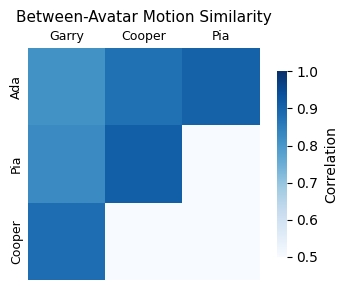

In [88]:
import matplotlib as mpl

mpl.rcParams['font.size'] = 10
label_fontsize = 12
tick_fontsize = 10
dpi_val = 500

fig, ax = plt.subplots(figsize=(4, 3))

sns.heatmap(color_map, cmap="Blues", vmin=0.5, vmax=1, square=True, linewidth=0, 
            cbar_kws={"label": "Correlation", "shrink":0.8}, ax=ax)
ax.set_title("Between-Avatar Motion Similarity", fontsize=11)
ax.set_xticklabels(x_tick_labels)
ax.set_yticklabels(y_tick_labels)
ax.xaxis.tick_top()
ax.tick_params(axis="both", length=0, labelsize=9)

fig.tight_layout()
fig.savefig(f"{results_path}/Figure4B_landm_CrossCorr_avatars_heatmap_annot_blues.svg", dpi=dpi_val)
plt.show(fig)

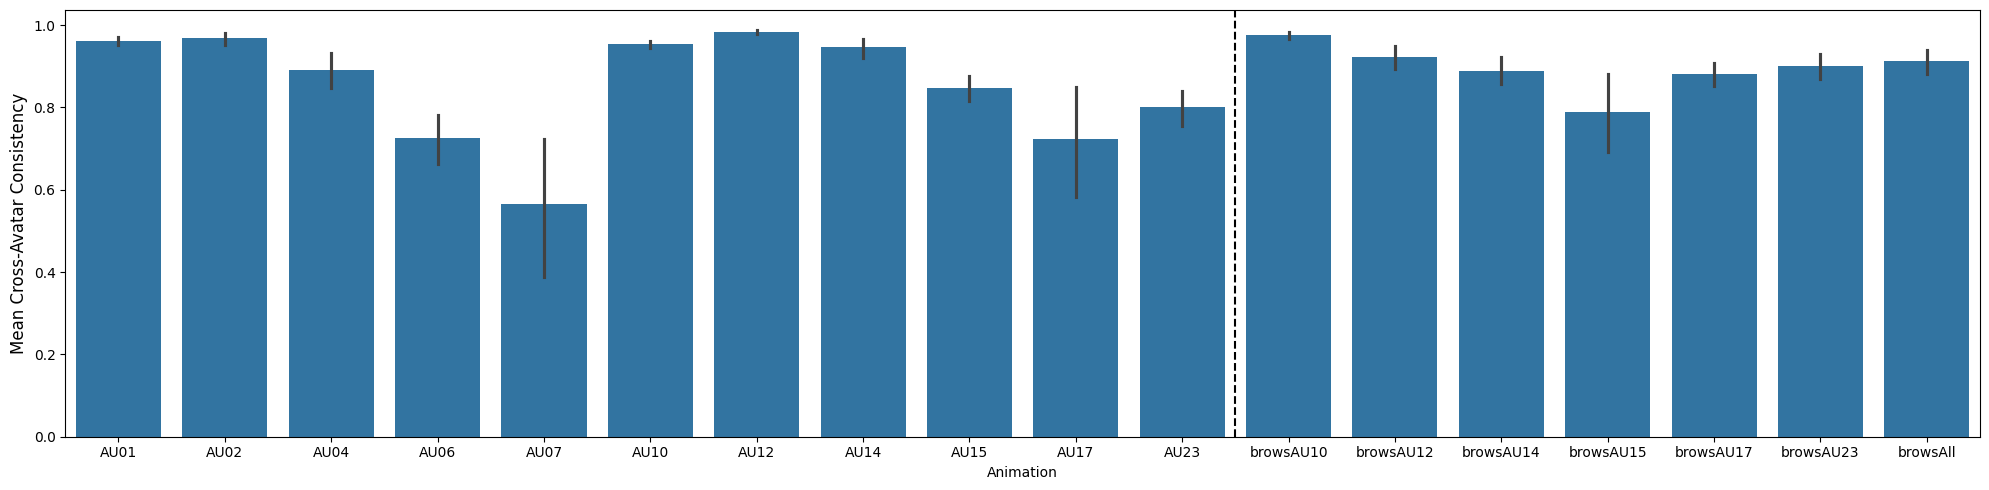

In [22]:
import matplotlib as mpl

# Manuscript styling
mpl.rcParams['font.size'] = 10
label_fontsize = 12
tick_fontsize = 10
dpi_val = 500

fig, ax = plt.subplots(figsize=(20,5))
sns.barplot(unique_pairs_df, x="Animation", y='pearsonr', ax=ax)
ax.set_ylabel("Mean Cross-Avatar Consistency", fontsize=label_fontsize)
ax.axvline(x=10.5, color="black", ls="--")
#ax.tick_params("x", rotation=45)

plt.subplots_adjust(right=0.7)
plt.tight_layout()
fig.savefig(f"{results_path}/Figure4C_animation_consistency_barplot_ci.svg", dpi=dpi_val)
plt.show()

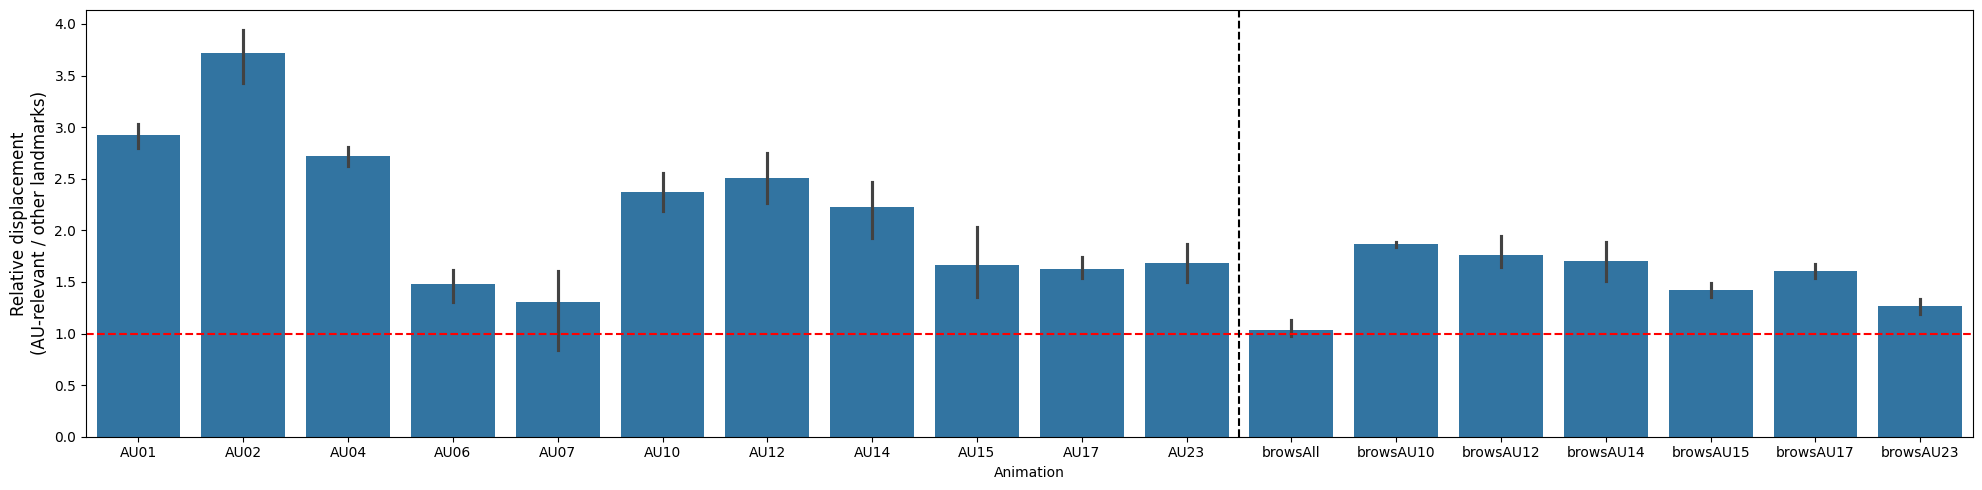

In [21]:
import matplotlib as mpl

# Manuscript styling
mpl.rcParams['font.size'] = 10
label_fontsize = 12
tick_fontsize = 10
dpi_val = 500

fig, ax = plt.subplots(figsize=(20,5))
sns.barplot(landm_actv_over_inactv_df, x="Animation", y='Mean_acc_reported', ax=ax)
#ax.tick_params("x", rotation=45)
ax.set_ylabel("Relative displacement\n(AU-relevant / other landmarks)", fontsize=label_fontsize)
ax.axhline(y=1, color="r", ls="--")
ax.axvline(x=10.5, color="black", ls="--")
plt.subplots_adjust(right=0.7)
plt.tight_layout()
fig.savefig(f"{results_path}/Figure4D_acc_ratio_barplot.svg", dpi=dpi_val)
plt.show()